# TinyGestureSSD (pretrained backbone variant) — Single-Scale SSDLite Hand Gesture Detector

Same single-scale SSDLite detector as the base notebook, with three changes aimed at the
same failure mode: a from-scratch backbone on ~3,900 images plateauing at low confidence.

- **Pretrained backbone.** `width_mult` is 1.0 here, not 0.5, specifically because torchvision
  only ships an ImageNet checkpoint at width_mult=1.0. Bigger than the original ~100K-param
  ESP32 target, on purpose — the point of this notebook is to check whether pretrained features
  actually fix convergence before spending effort shrinking it back down.
- **Anchors fit to the real dataset** instead of hand-picked. Section 7b measures actual box
  size/aspect ratio from your cached pseudo-labeled data and regenerates the anchor set from
  that, instead of the original guessed `48px` / `(1.0, 1.8)`.
- **Augmentation** (horizontal flip, scale jitter, color jitter) on the training split — the base
  notebook had none, which likely compounds the from-scratch problem on a dataset this size.

Anchor count and head architecture are unchanged (still 2 anchors/cell, 8x8 grid, 128 anchors
total) — only the anchor *geometry* and backbone *width/init* change, so this reuses the same
matching/loss/inference/export code as the base notebook essentially unmodified.

This notebook shares its `dataset/` cache with the base notebook and the KD notebook — the slow
MediaPipe pass only ever needs to run once across all three. Checkpoints and exports land in
`models_pretrained/`, kept separate so this run doesn't overwrite another notebook's output.

Run top to bottom, one pass — no resuming training in stages. Resuming restarts the cosine LR
schedule each time, which is a real bug this notebook avoids by design: pick an epoch count up
front (Section 1) and let it run.

## 0 — Setup

Local kernel, not Colab — no Drive mount, no Colab Secrets, no `!pip install` cells. Install once,
outside this notebook, into the kernel's environment:

```bash
python3.11 -m venv .venv && source .venv/bin/activate
pip install torch torchvision --index-url https://download.pytorch.org/whl/cu121   # match your driver
pip install -r requirements.txt
```

(Optional) if you have a Hugging Face token and want to avoid anonymous rate limits on the HaGRID
download, set it before launching Jupyter — the dataset is public, so this isn't required:

```bash
export HF_TOKEN=hf_...
```

In [1]:
import sys
print(sys.version)
import torch
print("torch:", torch.__version__, " CUDA available:", torch.cuda.is_available())

3.11.9 (tags/v3.11.9:de54cf5, Apr  2 2024, 10:12:12) [MSC v.1938 64 bit (AMD64)]
torch: 2.5.1+cu121  CUDA available: True


## 1 — Imports & Configuration

Every hyperparameter, class name, and path lives in this one cell. `PROJECT_ROOT` defaults to the
notebook's working directory — run this notebook from the same directory as the base notebook so
they share `dataset/`, or change the line below. Checkpoints/exports go to `models_pretrained/`,
separate from the base notebook's `models/` and the KD notebook's `models_kd/`.

In [2]:
import os
import random

import numpy as np
import torch
from tqdm.auto import tqdm

# ---- reproducibility --------------------------------------------------------
SEED = 0


def set_seed(seed: int = SEED) -> None:
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)


set_seed()

# ---- geometry -----------------------------------------------------------
IMG_SIZE = 128
STRIDE = 16                                # single tap point: 128 / 16 = 8x8 feature map
GRID_SIZE = IMG_SIZE // STRIDE             # 8
ASPECT_RATIOS = (1.0, 1.8)                 # 1:1 (fist/palm) + elongated (pointing)
NUM_ANCHORS_PER_CELL = len(ASPECT_RATIOS)  # 2
ANCHOR_BASE_PX = 48                        # base anchor size in pixels on the 128px frame
NUM_TOTAL_ANCHORS = GRID_SIZE * GRID_SIZE * NUM_ANCHORS_PER_CELL  # 8*8*2 = 128

# ---- backbone -------------------------------------------------------------
CUT_INDEX = 14                             # features[:14] -> output stride 16, 8x8
WIDTH_MULT = 1.0                           # torchvision only ships an ImageNet checkpoint at
                                            # width_mult=1.0 -- that's the whole point of this
                                            # notebook, so this is intentionally bigger than the
                                            # original ~100K-param ESP32 target. Shrinking back
                                            # down (pruning/distillation/lower width) is a later
                                            # step, only worth doing once this actually converges
                                            # well. See model.param_summary() below for the real
                                            # count once the backbone's built.

# ---- classes ----------------------------------------------------------------
CLASS_NAMES = ["fist", "palm", "like", "ok", "peace", "point"]
NUM_CLASSES = len(CLASS_NAMES)             # background is implicit class 0 in the head output

# ---- box encoding / matching -----------------------------------------------
VARIANCES = (0.1, 0.1, 0.2, 0.2)           # standard SSD-style scale factors for regression targets
POS_IOU_THRESH = 0.5
NEG_IOU_THRESH = 0.4
NEG_POS_RATIO = 3                          # hard-negative-mining ratio

# ---- dataset ----------------------------------------------------------------
HF_DATASET_ID = "cj-mills/hagrid-sample-30k-384p"
HAGRID_TO_PROJECT = {"fist": "fist", "palm": "palm", "like": "like",
                      "ok": "ok", "peace": "peace", "one": "point"}
WANTED_HAGRID_CLASSES = set(HAGRID_TO_PROJECT.keys())
MAX_IMAGES_PER_CLASS = 800                 # per-class cap before MediaPipe box extraction

# ---- training ----------------------------------------------------------------
BATCH_SIZE = 64
EPOCHS = 60                                 # one clean run, no resuming -- see title cell. Raise
                                             # this if val_f1 is still climbing at epoch 60 rather
                                             # than lower it if it plateaus early; stopping short
                                             # costs nothing since the checkpoint saved is always
                                             # the single best epoch regardless of how long you ran.
LR = 2e-3
WEIGHT_DECAY = 1e-4
SELECTION_METRIC = "f1_macro"              # which val metric selects the saved checkpoint

# ---- mediapipe (pseudo-label source for ground-truth boxes) -----------------
MEDIAPIPE_MODEL_URL = (
    "https://storage.googleapis.com/mediapipe-models/hand_landmarker/"
    "hand_landmarker/float16/latest/hand_landmarker.task"
)

# ---- paths ----------------------------------------------------------------
PROJECT_ROOT = os.getcwd()                 # run this notebook from your project root
MODELS_DIR = os.path.join(PROJECT_ROOT, "models_pretrained")  # checkpoints/ONNX/plots for THIS
                                                                # experiment only -- kept separate
                                                                # from the base and KD notebooks
                                                                # so runs don't overwrite each other
DATASET_DIR = os.path.join(PROJECT_ROOT, "dataset")            # shared across all three notebooks
os.makedirs(MODELS_DIR, exist_ok=True)
os.makedirs(DATASET_DIR, exist_ok=True)
MEDIAPIPE_MODEL_PATH = os.path.join(DATASET_DIR, "hand_landmarker.task")  # shared asset, not
                                                                            # experiment-specific
DATASET_CACHE_DIR = os.path.join(DATASET_DIR, "hagrid_pseudo_labeled")
CLASSES_FILE = os.path.join(DATASET_DIR, "classes.txt")
_LEGACY_DATASET_CACHE_DIR = os.path.join(PROJECT_ROOT, "models", "hagrid_pseudo_labeled")  # pre-dataset/ layout


# ---- device ----------------------------------------------------------------
def get_device() -> torch.device:
    device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
    if device.type == "cuda":
        torch.backends.cudnn.benchmark = True   # fixed 128x128 input shape -> let cuDNN pick fast kernels
        print(f"GPU: {torch.cuda.get_device_name(0)}")
    else:
        print("WARNING: no GPU detected -- running on CPU. Training will be much slower.")
    return device


device = get_device()
print(f"grid: {GRID_SIZE}x{GRID_SIZE}  anchors/cell: {NUM_ANCHORS_PER_CELL}  total anchors: {NUM_TOTAL_ANCHORS}")
print(f"classes: {CLASS_NAMES}  (+ background)")

GPU: NVIDIA GeForce RTX 2050
grid: 8x8  anchors/cell: 2  total anchors: 128
classes: ['fist', 'palm', 'like', 'ok', 'peace', 'point']  (+ background)


## 2 — Anchor Generation & Box Utilities

Fully vectorized anchor generation via `torch.meshgrid(..., indexing='ij')` — no Python loop over
cells or aspect ratios in the version actually used. Anchor order is row-major over cells, then
aspect ratio within each cell; the detection heads (Section 4) emit channels in this same order.
`_generate_anchors_loop_reference` is the slow, obviously-correct version, kept only to unit-test
the vectorized one.

The actual anchor geometry generated below (`ANCHOR_BASE_PX=48`, `ASPECT_RATIOS=(1.0, 1.8)`) is a
placeholder — Section 7b regenerates `anchors_center`/`anchors_corner` with numbers fit to the
real dataset once it's loaded. This cell exists to define the functions and give the anchor-count
math (`NUM_TOTAL_ANCHORS`, etc.) something concrete to sanity-check against early.

In [3]:
def generate_anchors(img_size, stride, base_size_px, aspect_ratios):
    """
    Vectorized anchor generation.
    Returns center-form anchors (cx, cy, w, h), normalized to [0, 1], shape (G*G*R, 4).
    Order: row-major over grid cells (row-major = row changes slowest), then aspect
    ratio within each cell (fastest-changing) -- must match the head's channel layout.
    """
    grid_size = img_size // stride
    base = base_size_px / img_size

    rows = torch.arange(grid_size, dtype=torch.float32)
    cols = torch.arange(grid_size, dtype=torch.float32)
    grid_r, grid_c = torch.meshgrid(rows, cols, indexing="ij")     # (G,G), row-major

    cy = ((grid_r + 0.5) * stride / img_size).reshape(-1)          # (G*G,)
    cx = ((grid_c + 0.5) * stride / img_size).reshape(-1)          # (G*G,)

    ratios = torch.tensor(aspect_ratios, dtype=torch.float32)      # (R,)
    R = ratios.shape[0]

    # repeat each cell's center R times contiguously -> ratio is the fast axis
    cx = cx.unsqueeze(1).expand(-1, R).reshape(-1)                 # (G*G*R,)
    cy = cy.unsqueeze(1).expand(-1, R).reshape(-1)

    w = (base * ratios.sqrt()).unsqueeze(0).expand(grid_size * grid_size, -1).reshape(-1)
    h = (base / ratios.sqrt()).unsqueeze(0).expand(grid_size * grid_size, -1).reshape(-1)

    return torch.stack([cx, cy, w, h], dim=-1)


def _generate_anchors_loop_reference(img_size, stride, base_size_px, aspect_ratios):
    """Slow, obviously-correct loop version -- used only to unit-test the vectorized one above."""
    grid_size = img_size // stride
    base = base_size_px / img_size
    out = []
    for row in range(grid_size):
        for col in range(grid_size):
            cx = (col + 0.5) * stride / img_size
            cy = (row + 0.5) * stride / img_size
            for ratio in aspect_ratios:
                w = base * (ratio ** 0.5)
                h = base / (ratio ** 0.5)
                out.append([cx, cy, w, h])
    return torch.tensor(out, dtype=torch.float32)


def verify_anchors(anchors_center, img_size, stride, base_size_px, aspect_ratios):
    """Asserts the vectorized anchors match the loop reference exactly. Call once at startup."""
    ref = _generate_anchors_loop_reference(img_size, stride, base_size_px, aspect_ratios)
    assert torch.allclose(anchors_center, ref), "vectorized anchors don't match the loop reference!"
    print("anchor generation verified against loop reference")


def center_to_corner(boxes):
    """(cx, cy, w, h) -> (x1, y1, x2, y2)"""
    cx, cy, w, h = boxes.unbind(-1)
    return torch.stack([cx - w / 2, cy - h / 2, cx + w / 2, cy + h / 2], dim=-1)


def corner_to_center(boxes):
    """(x1, y1, x2, y2) -> (cx, cy, w, h)"""
    x1, y1, x2, y2 = boxes.unbind(-1)
    return torch.stack([(x1 + x2) / 2, (y1 + y2) / 2, x2 - x1, y2 - y1], dim=-1)


def box_iou(boxes1, boxes2):
    """Vectorized pairwise IoU. boxes1: (N,4), boxes2: (M,4), corner-form -> (N,M)."""
    area1 = (boxes1[:, 2] - boxes1[:, 0]) * (boxes1[:, 3] - boxes1[:, 1])
    area2 = (boxes2[:, 2] - boxes2[:, 0]) * (boxes2[:, 3] - boxes2[:, 1])
    lt = torch.max(boxes1[:, None, :2], boxes2[None, :, :2])
    rb = torch.min(boxes1[:, None, 2:], boxes2[None, :, 2:])
    wh = (rb - lt).clamp(min=0)
    inter = wh[..., 0] * wh[..., 1]
    union = area1[:, None] + area2[None, :] - inter
    return inter / union.clamp(min=1e-8)


def box_iou_batch(gt_boxes_corner, anchors_corner):
    """
    Batched one-box-per-image IoU against the full anchor set -- no Python loop over the batch.
    gt_boxes_corner: (B,4), anchors_corner: (A,4) -> (B,A)
    """
    gt = gt_boxes_corner.unsqueeze(1)          # (B,1,4)
    an = anchors_corner.unsqueeze(0)           # (1,A,4)
    lt = torch.max(gt[..., :2], an[..., :2])
    rb = torch.min(gt[..., 2:], an[..., 2:])
    wh = (rb - lt).clamp(min=0)
    inter = wh[..., 0] * wh[..., 1]
    area_gt = (gt[..., 2] - gt[..., 0]) * (gt[..., 3] - gt[..., 1])
    area_an = (an[..., 2] - an[..., 0]) * (an[..., 3] - an[..., 1])
    union = area_gt + area_an - inter
    return inter / union.clamp(min=1e-8)

In [4]:
anchors_center = generate_anchors(IMG_SIZE, STRIDE, ANCHOR_BASE_PX, ASPECT_RATIOS)
verify_anchors(anchors_center, IMG_SIZE, STRIDE, ANCHOR_BASE_PX, ASPECT_RATIOS)
anchors_corner = center_to_corner(anchors_center)
anchors_center_d = anchors_center.to(device)
anchors_corner_d = anchors_corner.to(device)
print(f"anchors: {tuple(anchors_center.shape)}")

anchor generation verified against loop reference
anchors: (128, 4)


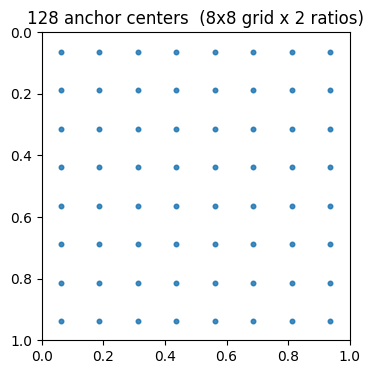

In [5]:
# quick visual sanity check of the anchor grid
import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(4, 4))
ax.scatter(anchors_center[:, 0], anchors_center[:, 1], s=10, alpha=0.6)
ax.set_xlim(0, 1)
ax.set_ylim(1, 0)
ax.set_aspect("equal")
ax.set_title(f"{anchors_center.shape[0]} anchor centers  ({GRID_SIZE}x{GRID_SIZE} grid x {NUM_ANCHORS_PER_CELL} ratios)")
plt.show()

## 3 — Backbone: Truncated MobileNetV2, ImageNet-Pretrained

`build_truncated_backbone` still slices `torchvision`'s MobileNetV2 features at `CUT_INDEX`, but
now loads the ImageNet-pretrained checkpoint first, at `width_mult=1.0` — torchvision doesn't ship
a checkpoint at any other width, which is why `WIDTH_MULT` moved to 1.0 in Section 1. Everything
downstream (channel inference in Section 4, anchor count, head shapes) already adapts to whatever
channel count the backbone produces, so this is the only place that needed to change.

In [6]:
import torch.nn as nn
import torchvision


def build_truncated_backbone(width_mult: float = WIDTH_MULT) -> nn.Module:
    if width_mult == 1.0:
        full = torchvision.models.mobilenet_v2(weights=torchvision.models.MobileNet_V2_Weights.IMAGENET1K_V1)
        print("backbone: ImageNet-pretrained MobileNetV2 (width_mult=1.0)")
    else:
        full = torchvision.models.mobilenet_v2(weights=None, width_mult=width_mult)
        print(f"backbone: from-scratch MobileNetV2 (width_mult={width_mult}) -- "
              f"no pretrained checkpoint exists at this width")
    return nn.Sequential(*list(full.features.children())[:CUT_INDEX])


def probe_backbone_blocks(width_mult: float = 1.0, img_size: int = IMG_SIZE):
    """Prints each MobileNetV2 block's output shape -- useful for picking CUT_INDEX."""
    full = torchvision.models.mobilenet_v2(weights=None, width_mult=width_mult)
    x = torch.zeros(1, 3, img_size, img_size)
    print(f"--- block-by-block probe (width_mult={width_mult}) ---")
    with torch.no_grad():
        for i, block in enumerate(full.features):
            x = block(x)
            print(f"{i:2d}  {type(block).__name__:20s}  {tuple(x.shape)}")

## 4 — SSDLite Detection Heads & Full Model

`SeparableHead` is the SSDLite-style depthwise-separable prediction head. Channel counts feeding
into the two heads are *inferred* from a dummy forward pass through the backbone, never
hard-coded, so `WIDTH_MULT` stays a single knob for the whole model's capacity.

In [7]:
class SeparableHead(nn.Module):
    """SSDLite-style prediction head: depthwise 3x3 (+BN+ReLU6) -> pointwise 1x1."""

    def __init__(self, in_channels: int, out_channels: int):
        super().__init__()
        self.depthwise = nn.Conv2d(in_channels, in_channels, kernel_size=3, padding=1,
                                    groups=in_channels, bias=False)
        self.bn = nn.BatchNorm2d(in_channels)
        self.act = nn.ReLU6(inplace=True)
        self.pointwise = nn.Conv2d(in_channels, out_channels, kernel_size=1, bias=True)

    def forward(self, x):
        x = self.act(self.bn(self.depthwise(x)))
        return self.pointwise(x)


def reshape_head_output(x, num_anchors_per_cell: int, out_per_anchor: int):
    """(B, A_cell*K, H, W) -> (B, H*W*A_cell, K), row-major cells then ratio-within-cell."""
    B, _, H, W = x.shape
    x = x.view(B, num_anchors_per_cell, out_per_anchor, H, W)
    x = x.permute(0, 3, 4, 1, 2).contiguous()          # (B, H, W, A_cell, K)
    return x.view(B, H * W * num_anchors_per_cell, out_per_anchor)


class SSDLiteGestureDetector(nn.Module):
    def __init__(self, num_classes: int = NUM_CLASSES, width_mult: float = WIDTH_MULT,
                 num_anchors_per_cell: int = NUM_ANCHORS_PER_CELL, img_size: int = IMG_SIZE):
        super().__init__()
        self.num_classes = num_classes
        self.num_anchors_per_cell = num_anchors_per_cell

        self.backbone = build_truncated_backbone(width_mult)

        # channel count is *inferred*, never hard-coded, so width_mult stays a single knob
        with torch.no_grad():
            feat = self.backbone(torch.zeros(1, 3, img_size, img_size))
        in_channels, grid = feat.shape[1], feat.shape[2]
        self.in_channels, self.grid_size = in_channels, grid

        self.cls_head = SeparableHead(in_channels, num_anchors_per_cell * (num_classes + 1))
        self.loc_head = SeparableHead(in_channels, num_anchors_per_cell * 4)

    def forward(self, x):
        feat = self.backbone(x)
        cls_out = reshape_head_output(self.cls_head(feat), self.num_anchors_per_cell, self.num_classes + 1)
        loc_out = reshape_head_output(self.loc_head(feat), self.num_anchors_per_cell, 4)
        return cls_out, loc_out                         # (B, num_anchors, C+1), (B, num_anchors, 4)

    def param_summary(self):
        def n(m):
            return sum(p.numel() for p in m.parameters())

        bb, cls_h, loc_h = n(self.backbone), n(self.cls_head), n(self.loc_head)
        total = bb + cls_h + loc_h
        print(f"{'backbone (mbv2 features[:14])':35s} {bb:>8,}")
        print(f"{'classification head':35s} {cls_h:>8,}")
        print(f"{'localization head':35s} {loc_h:>8,}")
        print("-" * 44)
        print(f"{'TOTAL':35s} {total:>8,}   (width_mult={WIDTH_MULT}; original on-device "
              f"budget was ~100,000 @ width_mult=0.35)")
        return total

In [8]:
model = SSDLiteGestureDetector().to(device)
model.param_summary()
print(f"\nbackbone output: {model.in_channels} channels @ {model.grid_size}x{model.grid_size}")

model.eval()
with torch.no_grad():
    _cls, _loc = model(torch.randn(4, 3, IMG_SIZE, IMG_SIZE, device=device))
print(f"forward OK -> cls {tuple(_cls.shape)}   loc {tuple(_loc.shape)}")

backbone: ImageNet-pretrained MobileNetV2 (width_mult=1.0)
backbone (mbv2 features[:14])        542,528
classification head                    2,414
localization head                      1,832
--------------------------------------------
TOTAL                                546,774   (width_mult=1.0; original on-device budget was ~100,000 @ width_mult=0.35)

backbone output: 96 channels @ 8x8
forward OK -> cls (4, 128, 7)   loc (4, 128, 4)


## 5 — Target Assignment (Anchor ↔ Ground-Truth Matching)

Box regression targets are encoded relative to their matched anchor (standard SSD
parameterization, scaled by `VARIANCES`). Matching is fully vectorized across the batch — every
image has exactly one ground-truth box, so `box_iou_batch` broadcasts `(B,4)` against `(A,4)` in a
single shot with no per-image Python loop. Anchors with IoU ≥ 0.5 are positive, IoU < 0.4 are
explicitly background, and the gap between is ignored (excluded from the loss entirely). The
single best-IoU anchor per image is always forced positive so every image contributes at least
one positive, even if no anchor clears 0.5.

In [9]:
def encode_boxes(gt_center, anchor_center, variances=VARIANCES):
    """Ground-truth center-form boxes -> SSD-style regression targets relative to their anchor."""
    g_cx, g_cy, g_w, g_h = gt_center.unbind(-1)
    a_cx, a_cy, a_w, a_h = anchor_center.unbind(-1)
    v1, v2, v3, v4 = variances
    t_cx = (g_cx - a_cx) / a_w / v1
    t_cy = (g_cy - a_cy) / a_h / v2
    t_w = torch.log(g_w / a_w) / v3
    t_h = torch.log(g_h / a_h) / v4
    return torch.stack([t_cx, t_cy, t_w, t_h], dim=-1)


def decode_boxes(pred_offsets, anchor_center, variances=VARIANCES):
    """Inverse of encode_boxes -- predicted offsets + anchor -> absolute center-form box."""
    t_cx, t_cy, t_w, t_h = pred_offsets.unbind(-1)
    a_cx, a_cy, a_w, a_h = anchor_center.unbind(-1)
    v1, v2, v3, v4 = variances
    p_cx = t_cx * v1 * a_w + a_cx
    p_cy = t_cy * v2 * a_h + a_cy
    p_w = torch.exp(t_w * v3) * a_w
    p_h = torch.exp(t_h * v4) * a_h
    return torch.stack([p_cx, p_cy, p_w, p_h], dim=-1)


def match_anchors_to_targets(gt_boxes_corner, gt_labels, anchors_center, anchors_corner,
                              pos_iou_thresh=POS_IOU_THRESH, neg_iou_thresh=NEG_IOU_THRESH):
    """
    Vectorized single-object-per-image anchor matching.
      gt_boxes_corner: (B,4) normalized (x1,y1,x2,y2)
      gt_labels:       (B,)  0-indexed foreground class id
    Returns:
      cls_targets: (B,A) long  -- 0=background, 1..num_classes=foreground, -1=ignore
      loc_targets: (B,A,4)     -- encoded regression targets (only valid where pos_mask is True)
      pos_mask:    (B,A) bool
      ignore_mask: (B,A) bool  -- 0.4 <= iou < 0.5, excluded from the loss entirely
    """
    B, A = gt_boxes_corner.shape[0], anchors_center.shape[0]

    iou = box_iou_batch(gt_boxes_corner, anchors_corner)            # (B,A)

    pos_mask = iou >= pos_iou_thresh
    forced_idx = iou.argmax(dim=1, keepdim=True)                    # guarantee >=1 positive/image
    pos_mask.scatter_(1, forced_idx, True)

    neg_mask = (iou < neg_iou_thresh) & (~pos_mask)
    ignore_mask = (~pos_mask) & (~neg_mask)

    cls_targets = torch.zeros(B, A, dtype=torch.long, device=gt_boxes_corner.device)
    cls_targets[pos_mask] = (gt_labels.unsqueeze(1).expand(B, A) + 1)[pos_mask]
    cls_targets[ignore_mask] = -1

    gt_center = corner_to_center(gt_boxes_corner)                   # (B,4)
    gt_center_exp = gt_center.unsqueeze(1).expand(B, A, 4)
    anchor_center_exp = anchors_center.unsqueeze(0).expand(B, A, 4)
    loc_targets = encode_boxes(gt_center_exp, anchor_center_exp)    # (B,A,4)

    return cls_targets, loc_targets, pos_mask, ignore_mask

In [10]:
# round-trip check: encode then decode should recover the original box exactly
dummy_gt = torch.rand(5, 4) * 0.5 + 0.25
dummy_anchor = anchors_center[:5]
encoded = encode_boxes(dummy_gt, dummy_anchor)
decoded = decode_boxes(encoded, dummy_anchor)
assert torch.allclose(dummy_gt, decoded, atol=1e-5), "encode/decode round-trip failed!"
print("encode/decode round-trip OK")

encode/decode round-trip OK


## 6 — MultiBox Loss (Smooth L1 + Cross-Entropy, 3:1 Hard Negative Mining)

Localization loss only ever touches matched-positive anchors — `loc_preds[pos_mask]` masks the
rest out entirely. For classification, every anchor gets a per-element cross-entropy loss first;
positive and ignored anchors are excluded from the negative-mining pool via `-inf`, then a
double-argsort (sort, then sort the sort) gives each remaining background anchor its rank by loss
magnitude with no Python loop over the batch or anchors. Keeping the top `3 * num_positives`
hardest negatives per image enforces the 3:1 ratio exactly, even when the ratio would require a
different cutoff per image in the batch.

In [11]:
import torch.nn.functional as F


class MultiBoxLoss(nn.Module):
    def __init__(self, neg_pos_ratio: int = NEG_POS_RATIO):
        super().__init__()
        self.neg_pos_ratio = neg_pos_ratio

    def forward(self, cls_preds, loc_preds, cls_targets, loc_targets, pos_mask, ignore_mask):
        B, A, C = cls_preds.shape

        # ---- localization: positives only ----
        loc_loss = F.smooth_l1_loss(loc_preds[pos_mask], loc_targets[pos_mask], reduction="sum")

        # ---- classification with 3:1 hard negative mining ----
        safe_targets = cls_targets.clamp(min=0)   # -1 (ignore) -> 0 just so CE doesn't error; excluded below
        loss_per_anchor = F.cross_entropy(
            cls_preds.view(-1, C), safe_targets.view(-1), reduction="none"
        ).view(B, A)

        loss_for_ranking = loss_per_anchor.clone()
        loss_for_ranking[pos_mask] = float("-inf")     # never select positives as "negatives"
        loss_for_ranking[ignore_mask] = float("-inf")  # never select ignored anchors either

        num_pos = pos_mask.sum(dim=1, keepdim=True)                          # (B,1)
        num_neg_avail = (~pos_mask & ~ignore_mask).sum(dim=1, keepdim=True)
        num_neg = torch.clamp(self.neg_pos_ratio * num_pos, max=num_neg_avail)

        _, loss_idx = loss_for_ranking.sort(dim=1, descending=True)
        _, rank = loss_idx.sort(dim=1)               # rank[b,a] = position of anchor a in the sorted order
        hard_neg_mask = rank < num_neg

        selected = pos_mask | hard_neg_mask
        cls_loss = loss_per_anchor[selected].sum()

        num_pos_total = num_pos.sum().clamp(min=1).float()
        loc_loss = loc_loss / num_pos_total
        cls_loss = cls_loss / num_pos_total
        return loc_loss + cls_loss, loc_loss, cls_loss

In [12]:
# sanity check with random dummy predictions
criterion = MultiBoxLoss().to(device)
dummy_cls = torch.randn(4, NUM_TOTAL_ANCHORS, NUM_CLASSES + 1, device=device)
dummy_loc = torch.randn(4, NUM_TOTAL_ANCHORS, 4, device=device)
dummy_boxes = (torch.rand(4, 4, device=device) * 0.5 + 0.25)
dummy_labels = torch.randint(0, NUM_CLASSES, (4,), device=device)

cls_t, loc_t, pos_m, ign_m = match_anchors_to_targets(dummy_boxes, dummy_labels, anchors_center_d, anchors_corner_d)
total_loss, loc_loss, cls_loss = criterion(dummy_cls, dummy_loc, cls_t, loc_t, pos_m, ign_m)
print(f"dummy loss -> total={total_loss.item():.4f}  loc={loc_loss.item():.4f}  cls={cls_loss.item():.4f}")

dummy loss -> total=nan  loc=nan  cls=16.8304


## 7 — Real Dataset: HaGRID (images) + MediaPipe Hand Landmarker (boxes)

The `cj-mills/hagrid-sample-30k-384p` variant used here has no `bboxes` column (image + label
only), so ground-truth boxes are pseudo-labeled by running MediaPipe's Hand Landmarker — a real
trained detector, not a color heuristic — on each kept image and taking the largest detected
hand's bounding box (padded 10%). The gesture *class* label still comes from HaGRID itself;
MediaPipe only supplies the box.

The MediaPipe pass takes a long time (tens of minutes for a few thousand images), so its output is
cached to disk (`DATASET_CACHE_DIR`, now under a dedicated top-level `dataset/` folder rather than
inside `models/`) and reused on subsequent runs instead of being recomputed every time.
`prepare_dataset()` also checks for a dataset already cached at the *old* `models/`-based location
from a previous run of this notebook, and moves it into `dataset/` instead of recomputing —
migration, not deletion. A `classes.txt` (one class name per line, same order as `CLASS_NAMES`)
gets written into `dataset/` alongside the data so the folder is self-describing.

**Progress bars added here:** the per-class capping loop and the MediaPipe detection loop both
report progress now — the capping loop used to run silent, and the MediaPipe loop is the single
longest step in the whole notebook.

**Memory fix:** the previous version loaded every kept image into a Python list up front
(`images_in_memory = capped["image"]`) before running detection on any of them — for ~4,800 images
that's a multi-GB spike held in RAM simultaneously, on top of Python, PyTorch, MediaPipe, and
whatever else is running. On an 8 GB machine that's enough to push the system into swap, which
looks exactly like a hang: CPU usage drops, nothing crashes, nothing progresses. This version pulls
one image at a time inside the detection loop instead, so peak memory stays roughly constant
regardless of dataset size.

**New in this notebook: training-time augmentation.** `HaGRIDGestureDataset` now takes an
`augment` flag — on for the train split, off for val. Three box-coordinate-aware transforms,
applied in order: random horizontal flip, random scale jitter (±15%, zoom in/out around center),
then color jitter (brightness/contrast/saturation/hue) last since it doesn't touch geometry. None
of your 6 classes are direction-sensitive (`point` is one class regardless of which way the finger
points), so flipping is safe here — that wouldn't hold if you ever split gestures by handedness.
Section 7c below renders a few augmented training samples with their boxes drawn, specifically so
you can eyeball that the box transforms are correct before spending a full training run on it.

In [13]:
import shutil
import time

from datasets import load_dataset, load_from_disk
from huggingface_hub import login

import mediapipe as mp
from mediapipe.tasks import python as mp_python
from mediapipe.tasks.python import vision as mp_vision


# ---------------------------------------------------------------------------
# HaGRID download + per-class capping
# ---------------------------------------------------------------------------

def _load_raw_hagrid():
    hf_token = os.environ.get("HF_TOKEN")
    if hf_token:
        login(token=hf_token)
        print("logged in to Hugging Face Hub via HF_TOKEN env var")

    print(f"downloading / loading cached copy of {HF_DATASET_ID} ...")
    raw_ds = load_dataset(HF_DATASET_ID)

    hagrid_label_names = [name.replace("train_val_", "")
                           for name in raw_ds["train"].features["label"].names]
    print("HaGRID classes in this sample:", hagrid_label_names)
    return raw_ds, hagrid_label_names


def _cap_per_class(raw_ds, hagrid_label_names):
    all_labels = raw_ds["train"]["label"]
    print(f"read {len(all_labels)} labels")

    rng = random.Random(SEED)
    by_class_idx = {c: [] for c in WANTED_HAGRID_CLASSES}
    order = list(range(len(all_labels)))
    rng.shuffle(order)

    pbar = tqdm(order, desc="capping per class")
    for i in pbar:
        cname = hagrid_label_names[all_labels[i]]
        if cname in WANTED_HAGRID_CLASSES and len(by_class_idx[cname]) < MAX_IMAGES_PER_CLASS:
            by_class_idx[cname].append(i)
        if all(len(v) >= MAX_IMAGES_PER_CLASS for v in by_class_idx.values()):
            pbar.set_postfix(status="cap reached, stopping early")
            break

    keep_indices = sorted(idx for idxs in by_class_idx.values() for idx in idxs)
    capped = raw_ds["train"].select(keep_indices)

    print("materializing the capped subset into its own compact file...")
    capped = capped.flatten_indices()

    print("per-class counts after capping:", {c: len(v) for c, v in by_class_idx.items()})
    print(f"total images going into box extraction: {len(capped)}")
    return capped


# ---------------------------------------------------------------------------
# MediaPipe Hand Landmarker pseudo-labeling
# ---------------------------------------------------------------------------

def _detect_hand_bbox(landmarker, pil_image, pad_frac=0.10):
    """
    Runs the real Hand Landmarker (not a color heuristic) on one PIL image.
    Returns (x1, y1, x2, y2) normalized to [0,1], or None if no hand found.

    If multiple hands are detected, picks the one with the larger bounding box -- the
    gesture-performing hand is usually the more prominent one. MediaPipe has no way to
    know which hand matches this row's *label*, only that a hand is present, so this is
    still a heuristic pick, just a much more reliable one than color thresholding.
    """
    rgb = np.array(pil_image.convert("RGB"))
    mp_image = mp.Image(image_format=mp.ImageFormat.SRGB, data=rgb)
    result = landmarker.detect(mp_image)

    if not result.hand_landmarks:
        return None

    candidates = []
    for hand in result.hand_landmarks:
        xs = [lm.x for lm in hand]
        ys = [lm.y for lm in hand]
        x1, y1, x2, y2 = min(xs), min(ys), max(xs), max(ys)
        candidates.append((x1, y1, x2, y2, (x2 - x1) * (y2 - y1)))

    x1, y1, x2, y2, _ = max(candidates, key=lambda c: c[4])   # largest box wins

    pw, ph = (x2 - x1) * pad_frac, (y2 - y1) * pad_frac
    x1, x2 = max(0.0, x1 - pw), min(1.0, x2 + pw)
    y1, y2 = max(0.0, y1 - ph), min(1.0, y2 + ph)
    return (x1, y1, x2, y2)


def _extract_boxes_with_mediapipe(capped, hagrid_label_names):
    if not os.path.exists(MEDIAPIPE_MODEL_PATH):
        import urllib.request
        print(f"downloading hand landmarker model to {MEDIAPIPE_MODEL_PATH} ...")
        urllib.request.urlretrieve(MEDIAPIPE_MODEL_URL, MEDIAPIPE_MODEL_PATH)
        print(f"  done, {os.path.getsize(MEDIAPIPE_MODEL_PATH) / 1e6:.1f} MB")
    else:
        print(f"model already present at {MEDIAPIPE_MODEL_PATH}")

    base_options = mp_python.BaseOptions(model_asset_path=MEDIAPIPE_MODEL_PATH)
    landmarker_options = mp_vision.HandLandmarkerOptions(
        base_options=base_options,
        num_hands=2,
        running_mode=mp_vision.RunningMode.IMAGE,
    )
    landmarker = mp_vision.HandLandmarker.create_from_options(landmarker_options)

    # pull one row at a time instead of `capped["image"]`, which decodes every image in the
    # split into a Python list up front -- for a few thousand images that's a multi-GB spike
    # held in RAM simultaneously, on top of PyTorch/MediaPipe/everything else already running.
    # on an 8GB machine that's enough to push the system into swap, which looks exactly like a
    # hang: CPU usage drops, nothing crashes, nothing progresses. streaming keeps peak memory
    # roughly constant regardless of dataset size.
    n_images = len(capped)
    final_boxes, keep_mask = [], []
    pbar = tqdm(range(n_images), desc="MediaPipe hand detection", unit="img")
    t0 = time.time()
    for i in pbar:
        img = capped[i]["image"]
        box = _detect_hand_bbox(landmarker, img)
        keep_mask.append(box is not None)
        final_boxes.append(box)
        n_done = len(final_boxes)
        pbar.set_postfix(hit_rate=f"{sum(keep_mask) / n_done:.0%}")
    elapsed = time.time() - t0
    print(f"  done in {elapsed:.1f}s  ({elapsed / max(n_images, 1) * 1000:.0f} ms/image)")

    n_found = sum(keep_mask)
    print(f"hand detected in {n_found}/{n_images} images ({n_found / n_images:.1%})")

    detected_indices = [i for i, keep in enumerate(keep_mask) if keep]
    final_ds = capped.select(detected_indices)
    final_ds = final_ds.add_column("bbox", [final_boxes[i] for i in detected_indices])

    class_counts = {c: 0 for c in CLASS_NAMES}
    for lbl in final_ds["label"]:
        class_counts[HAGRID_TO_PROJECT[hagrid_label_names[lbl]]] += 1
    print("final class balance:", class_counts)
    return final_ds


# ---------------------------------------------------------------------------
# Training-time augmentation (box-coordinate-aware)
# ---------------------------------------------------------------------------

_COLOR_JITTER = torchvision.transforms.ColorJitter(brightness=0.25, contrast=0.25,
                                                      saturation=0.2, hue=0.02)


def _hflip(img, box_norm):
    """50% chance horizontal flip. Safe for this class list -- none of CLASS_NAMES are
    direction-sensitive (`point` is one class regardless of which way the finger points)."""
    if random.random() < 0.5:
        img = img.transpose(Image.FLIP_LEFT_RIGHT)
        x1, y1, x2, y2 = box_norm
        box_norm = np.array([1.0 - x2, y1, 1.0 - x1, y2], dtype=np.float32)
    return img, box_norm


def _scale_jitter(img, box_norm, scale_range=(0.85, 1.15)):
    """
    Zooms in/out around the image center by a random factor and returns an image of the
    same size. A point at normalized position p maps to 0.5 + (p-0.5)*scale regardless of
    zoom direction -- only the PIL operation differs (crop+resize to zoom in,
    shrink+pad to zoom out). img must already be square (IMG_SIZE x IMG_SIZE).
    """
    scale = random.uniform(*scale_range)
    S = img.size[0]

    if scale >= 1.0:
        crop = S / scale
        left = top = (S - crop) / 2
        img = img.crop((left, top, left + crop, top + crop)).resize((S, S), Image.BILINEAR)
    else:
        new_s = max(1, int(S * scale))
        img_small = img.resize((new_s, new_s), Image.BILINEAR)
        pad_color = tuple(np.array(img).reshape(-1, 3).mean(axis=0).astype(int).tolist())
        canvas = Image.new("RGB", (S, S), pad_color)
        canvas.paste(img_small, ((S - new_s) // 2, (S - new_s) // 2))
        img = canvas

    x1, y1, x2, y2 = box_norm
    x1, x2 = 0.5 + (x1 - 0.5) * scale, 0.5 + (x2 - 0.5) * scale
    y1, y2 = 0.5 + (y1 - 0.5) * scale, 0.5 + (y2 - 0.5) * scale
    return img, np.clip([x1, y1, x2, y2], 0.0, 1.0).astype(np.float32)


def augment_sample(img, box_norm):
    """img: PIL Image already resized to IMG_SIZE x IMG_SIZE. box_norm: [x1,y1,x2,y2] in [0,1]."""
    img, box_norm = _hflip(img, box_norm)
    img, box_norm = _scale_jitter(img, box_norm)
    img = _COLOR_JITTER(img)   # geometry-independent -- always last
    return img, box_norm


# ---------------------------------------------------------------------------
# PyTorch Dataset / DataLoaders
# ---------------------------------------------------------------------------

class HaGRIDGestureDataset(torch.utils.data.Dataset):
    def __init__(self, hf_split, hagrid_label_names, img_size: int = IMG_SIZE, augment: bool = False):
        self.ds = hf_split
        self.hagrid_label_names = hagrid_label_names
        self.img_size = img_size
        self.augment = augment

    def __len__(self):
        return len(self.ds)

    def __getitem__(self, idx):
        row = self.ds[idx]
        img = row["image"]
        if img.mode != "RGB":
            img = img.convert("RGB")
        img = img.resize((self.img_size, self.img_size), Image.BILINEAR)

        box_norm = np.array(row["bbox"], dtype=np.float32)
        box_norm = np.clip(box_norm, 0.0, 1.0)

        if self.augment:
            img, box_norm = augment_sample(img, box_norm)

        box_t = torch.from_numpy(box_norm).clamp(0.0, 1.0)

        label_name = HAGRID_TO_PROJECT[self.hagrid_label_names[row["label"]]]
        label_t = torch.tensor(CLASS_NAMES.index(label_name), dtype=torch.long)

        image_t = torch.from_numpy(np.array(img)).permute(2, 0, 1).float() / 255.0
        return image_t, box_t, label_t


def prepare_dataset(force_rebuild: bool = False, augment_train: bool = True):
    """
    Returns (train_loader, val_loader, hagrid_label_names).

    Caches the MediaPipe-pseudo-labeled dataset to DATASET_CACHE_DIR (under the top-level
    dataset/ folder) so the (slow) MediaPipe pass only ever runs once per
    MAX_IMAGES_PER_CLASS/SEED combination. Pass force_rebuild=True to ignore an existing cache
    and recompute it.

    If a dataset from an older run of this notebook is still sitting at the legacy
    models/hagrid_pseudo_labeled location, it gets moved into dataset/ instead of recomputed.

    augment_train=True applies random flip/scale/color augmentation to the train split only.
    """
    raw_ds, hagrid_label_names = _load_raw_hagrid()   # cheap; needed either way for label names

    if (not os.path.isdir(DATASET_CACHE_DIR)) and os.path.isdir(_LEGACY_DATASET_CACHE_DIR):
        print(f"found a dataset cached at the old location ({_LEGACY_DATASET_CACHE_DIR}) -- "
              f"moving it to {DATASET_CACHE_DIR} instead of recomputing it")
        shutil.move(_LEGACY_DATASET_CACHE_DIR, DATASET_CACHE_DIR)

    if os.path.isdir(DATASET_CACHE_DIR) and not force_rebuild:
        print(f"found cached pseudo-labeled dataset at {DATASET_CACHE_DIR}, skipping MediaPipe pass")
        final_ds = load_from_disk(DATASET_CACHE_DIR)
    else:
        capped = _cap_per_class(raw_ds, hagrid_label_names)
        final_ds = _extract_boxes_with_mediapipe(capped, hagrid_label_names)
        print(f"caching pseudo-labeled dataset to {DATASET_CACHE_DIR} for future runs...")
        final_ds.save_to_disk(DATASET_CACHE_DIR)

    if not os.path.exists(CLASSES_FILE):
        with open(CLASSES_FILE, "w") as f:
            f.write("\n".join(CLASS_NAMES) + "\n")
        print(f"wrote class list to {CLASSES_FILE}")

    final_ds = final_ds.shuffle(seed=SEED)
    n_val = max(1, int(0.1 * len(final_ds)))
    hf_val = final_ds.select(range(n_val))
    hf_train = final_ds.select(range(n_val, len(final_ds)))
    print(f"train: {len(hf_train)}   val: {len(hf_val)}   (augment_train={augment_train})")

    train_ds = HaGRIDGestureDataset(hf_train, hagrid_label_names, augment=augment_train)
    val_ds = HaGRIDGestureDataset(hf_val, hagrid_label_names, augment=False)

    train_loader = torch.utils.data.DataLoader(train_ds, batch_size=BATCH_SIZE, shuffle=True,
                                                 num_workers=0, pin_memory=torch.cuda.is_available())
    val_loader = torch.utils.data.DataLoader(val_ds, batch_size=BATCH_SIZE, shuffle=False,
                                               num_workers=0, pin_memory=torch.cuda.is_available())

    imgs, boxes, labels = next(iter(train_loader))
    print("batch:", tuple(imgs.shape), tuple(boxes.shape), tuple(labels.shape))

    return train_loader, val_loader, hagrid_label_names

In [14]:
from PIL import Image

train_loader, val_loader, hagrid_label_names = prepare_dataset()

downloading / loading cached copy of cj-mills/hagrid-sample-30k-384p ...
HaGRID classes in this sample: ['call', 'dislike', 'fist', 'four', 'like', 'mute', 'ok', 'one', 'palm', 'peace', 'peace_inverted', 'rock', 'stop', 'stop_inverted', 'three', 'three2', 'two_up', 'two_up_inverted']
found cached pseudo-labeled dataset at c:\Users\xared\Documents\30_PROJECTS\TinyGestureSSD\TinyGestureSSD\dataset\hagrid_pseudo_labeled, skipping MediaPipe pass
train: 3906   val: 433   (augment_train=True)
batch: (64, 3, 128, 128) (64, 4) (64,)


## 7b — Refit Anchors to the Real Box Distribution

`ANCHOR_BASE_PX = 48` and `ASPECT_RATIOS = (1.0, 1.8)` in Section 1 were hand-picked guesses.
Now that the dataset is loaded, its `bbox` column has the real answer — measure actual box size
and aspect ratio directly instead of guessing. The anchor *count* stays at 2 per cell (so nothing
about the head architecture changes, only the anchor geometry), using the 25th/75th percentile of
the real width/height ratio as the two representative aspect ratios, and the median box scale
(√(w·h)) as the base size. `anchors_center`/`anchors_corner` (and their `_d` device copies) get
regenerated in place with the fitted numbers, overriding Section 2's placeholder anchors —
everything downstream (matching, loss, model heads) already reads from these same variable names,
so nothing else needs to change.

In [15]:
def _box_wh_px(hf_split):
    boxes = np.array(hf_split["bbox"], dtype=np.float32)   # (N,4) x1,y1,x2,y2 normalized
    w = (boxes[:, 2] - boxes[:, 0]) * IMG_SIZE
    h = (boxes[:, 3] - boxes[:, 1]) * IMG_SIZE
    return w, h

w_train, h_train = _box_wh_px(train_loader.dataset.ds)
w_val, h_val = _box_wh_px(val_loader.dataset.ds)
w_all = np.concatenate([w_train, w_val])
h_all = np.concatenate([h_train, h_val])
ratio_all = w_all / h_all
scale_all = np.sqrt(w_all * h_all)

print(f"box width  (px): min={w_all.min():.1f}  median={np.median(w_all):.1f}  max={w_all.max():.1f}")
print(f"box height (px): min={h_all.min():.1f}  median={np.median(h_all):.1f}  max={h_all.max():.1f}")
print(f"box w/h ratio:    min={ratio_all.min():.2f}  median={np.median(ratio_all):.2f}  max={ratio_all.max():.2f}")

fitted_base_px = float(np.median(scale_all))
fitted_ratio_lo = float(np.percentile(ratio_all, 25))
fitted_ratio_hi = float(np.percentile(ratio_all, 75))

print(f"\nold  ANCHOR_BASE_PX={ANCHOR_BASE_PX}   ASPECT_RATIOS={ASPECT_RATIOS}")
print(f"new  ANCHOR_BASE_PX={fitted_base_px:.1f}   ASPECT_RATIOS=({fitted_ratio_lo:.2f}, {fitted_ratio_hi:.2f})")

ANCHOR_BASE_PX = fitted_base_px
ASPECT_RATIOS = (fitted_ratio_lo, fitted_ratio_hi)

anchors_center = generate_anchors(IMG_SIZE, STRIDE, ANCHOR_BASE_PX, ASPECT_RATIOS)
anchors_corner = center_to_corner(anchors_center)
anchors_center_d = anchors_center.to(device)
anchors_corner_d = anchors_corner.to(device)
print(f"\nanchors regenerated: {tuple(anchors_center.shape)}  (count unchanged, geometry refit)")

box width  (px): min=1.9  median=15.1  max=74.1
box height (px): min=4.9  median=19.8  max=106.4
box w/h ratio:    min=0.15  median=0.84  max=3.47

old  ANCHOR_BASE_PX=48   ASPECT_RATIOS=(1.0, 1.8)
new  ANCHOR_BASE_PX=17.1   ASPECT_RATIOS=(0.57, 1.08)

anchors regenerated: (128, 4)  (count unchanged, geometry refit)


## 7c — Sanity-Check the Augmentation

Renders 6 random *training-split* samples with augmentation applied and their box drawn, so you
can confirm the flip/scale transforms are moving the box correctly before committing a full
training run to it. If any box looks visibly off relative to the hand in the image, stop here —
don't train on it.

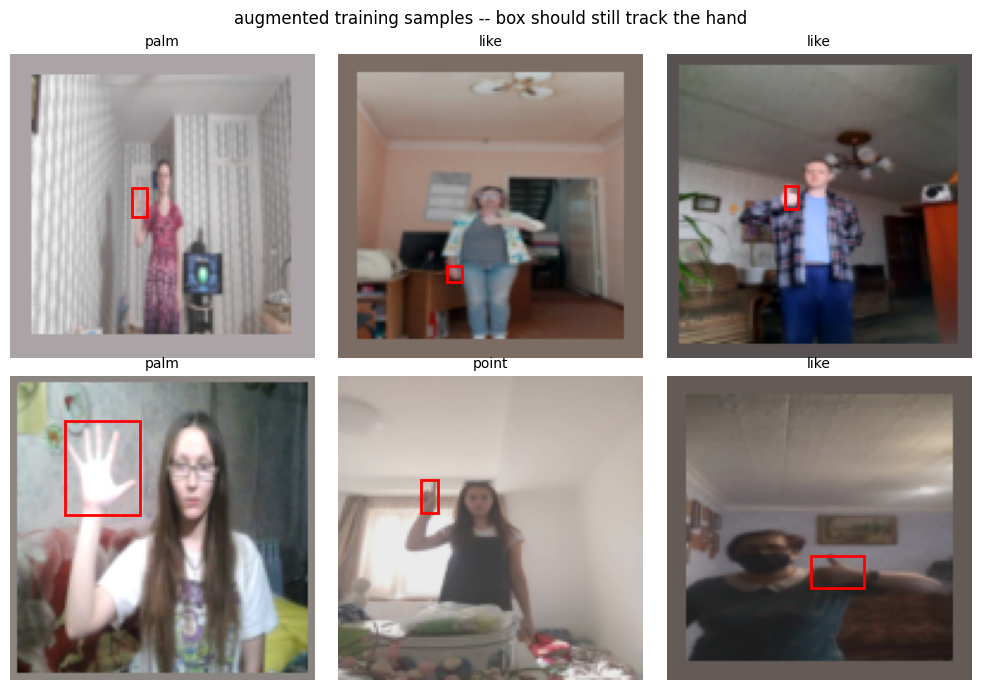

In [16]:
import matplotlib.patches as patches

train_ds_raw = train_loader.dataset
fig, axes = plt.subplots(2, 3, figsize=(10, 7))
sample_idxs = random.sample(range(len(train_ds_raw)), 6)
for idx, ax in zip(sample_idxs, axes.flat):
    img_t, box_t, label_t = train_ds_raw[idx]
    img_np = img_t.permute(1, 2, 0).numpy()
    x1, y1, x2, y2 = (box_t * IMG_SIZE).tolist()
    ax.imshow(img_np)
    ax.add_patch(patches.Rectangle((x1, y1), x2 - x1, y2 - y1, fill=False,
                                    edgecolor="red", linewidth=2))
    ax.set_title(CLASS_NAMES[label_t.item()], fontsize=10)
    ax.axis("off")
fig.suptitle("augmented training samples -- box should still track the hand")
fig.tight_layout()
plt.show()

## 8 — Training Loop, with Per-Epoch Accuracy / Precision / Recall / F1

`SELECTION_METRIC` picks which validation metric selects the checkpoint that gets saved —
macro-F1 by default, since it balances precision and recall and weights all 6 gesture classes
equally regardless of how many validation examples each one has. Per-*iteration* (not just
per-epoch) loss is recorded too, in `history["iter_total"]` / `["iter_loc"]` / `["iter_cls"]`, so
you can plot the raw training curve instead of only `EPOCHS` epoch-averaged points.

**Run this once, straight through, for the full `EPOCHS` budget.** `train_model` builds a fresh
`CosineAnnealingLR(T_max=epochs)` every call — calling it again to "continue" training restarts
the schedule from the top, which re-perturbs weights that were already most of the way annealed.
If `val_f1` is still climbing when this finishes, raise `EPOCHS` in Section 1 and rerun the whole
notebook from Section 8 down (not from scratch — `model` already holds the pretrained backbone,
this just means a longer single schedule next time), rather than calling `train_model` again on
top of itself.

**Progress bars added here:** an outer bar tracks overall epoch progress (with ETA across the
whole run, not just the current epoch), the inner per-batch bar now collapses after each epoch
instead of stacking up, and validation — previously silent — gets its own bar too.

In [17]:
from sklearn.metrics import accuracy_score, precision_recall_fscore_support


@torch.no_grad()
def predict_batch_labels(model, imgs, anchors_center, conf_thresh: float = 0.5):
    """
    Returns pred_labels: (B,) long tensor, project class id, or -1 if nothing cleared
    conf_thresh. Used for fast per-epoch validation (batched version of the single-image
    detector in Section 9).
    """
    cls_preds, loc_preds = model(imgs)                       # (B,A,C+1), (B,A,4)
    probs = F.softmax(cls_preds, dim=-1)
    fg_probs = probs[..., 1:]
    best_score_per_anchor, best_cls_per_anchor = fg_probs.max(dim=-1)      # (B,A)

    thresholded = best_score_per_anchor.masked_fill(best_score_per_anchor < conf_thresh, -1.0)
    best_score, best_anchor_idx = thresholded.max(dim=-1)                  # (B,)

    pred_labels = best_cls_per_anchor.gather(1, best_anchor_idx.unsqueeze(1)).squeeze(1)
    pred_labels = torch.where(best_score >= 0, pred_labels, torch.full_like(pred_labels, -1))
    return pred_labels


@torch.no_grad()
def evaluate(model, loader, anchors_center, device, conf_thresh: float = 0.5):
    """Runs the detector over a loader and computes classification-style metrics on the
    gesture label of the single detected hand (a missed detection counts as a wrong
    prediction)."""
    model.eval()
    all_preds, all_gts = [], []
    for imgs, boxes, labels in tqdm(loader, desc="validating", leave=False):
        imgs, labels = imgs.to(device), labels.to(device)
        preds = predict_batch_labels(model, imgs, anchors_center, conf_thresh)
        all_preds.append(preds.cpu())
        all_gts.append(labels.cpu())
    all_preds = torch.cat(all_preds).numpy()
    all_gts = torch.cat(all_gts).numpy()

    accuracy = accuracy_score(all_gts, all_preds)
    precision, recall, f1, _ = precision_recall_fscore_support(
        all_gts, all_preds, labels=list(range(NUM_CLASSES)), average="macro", zero_division=0
    )
    n_missed = int((all_preds == -1).sum())
    return {"accuracy": accuracy, "precision": precision, "recall": recall,
            "f1_macro": f1, "n_missed": n_missed, "n_total": len(all_gts)}


def train_model(model, train_loader, val_loader, anchors_center, anchors_corner, device,
                 epochs: int = EPOCHS, lr: float = LR, weight_decay: float = WEIGHT_DECAY,
                 selection_metric: str = SELECTION_METRIC):
    criterion = MultiBoxLoss().to(device)
    optimizer = torch.optim.AdamW(model.parameters(), lr=lr, weight_decay=weight_decay)
    scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=epochs)

    history = {
        "total": [], "loc": [], "cls": [],
        "val_accuracy": [], "val_precision": [], "val_recall": [], "val_f1_macro": [],
        "iter_total": [], "iter_loc": [], "iter_cls": [],   # per-iteration, never reset
    }

    best_metric_value = -1.0
    best_state_dict = None
    best_epoch = -1

    epoch_bar = tqdm(range(1, epochs + 1), desc="training", unit="epoch")
    for epoch in epoch_bar:
        model.train()
        running = {"total": 0.0, "loc": 0.0, "cls": 0.0}
        n_batches = 0

        batch_bar = tqdm(train_loader, desc=f"epoch {epoch}/{epochs}", leave=False)
        for imgs, boxes, labels in batch_bar:
            imgs, boxes, labels = imgs.to(device), boxes.to(device), labels.to(device)

            cls_preds, loc_preds = model(imgs)
            cls_t, loc_t, pos_m, ign_m = match_anchors_to_targets(boxes, labels, anchors_center, anchors_corner)
            total_loss, loc_loss, cls_loss = criterion(cls_preds, loc_preds, cls_t, loc_t, pos_m, ign_m)

            optimizer.zero_grad()
            total_loss.backward()
            torch.nn.utils.clip_grad_norm_(model.parameters(), max_norm=5.0)
            optimizer.step()

            history["iter_total"].append(total_loss.item())
            history["iter_loc"].append(loc_loss.item())
            history["iter_cls"].append(cls_loss.item())

            running["total"] += total_loss.item()
            running["loc"] += loc_loss.item()
            running["cls"] += cls_loss.item()
            n_batches += 1

            batch_bar.set_postfix(total=running["total"] / n_batches,
                                   loc=running["loc"] / n_batches,
                                   cls=running["cls"] / n_batches)

        scheduler.step()
        for k in ("total", "loc", "cls"):
            history[k].append(running[k] / n_batches)

        val_metrics = evaluate(model, val_loader, anchors_center, device)
        for k in ("accuracy", "precision", "recall", "f1_macro"):
            history[f"val_{k}"].append(val_metrics[k])

        is_best = val_metrics[selection_metric] > best_metric_value
        if is_best:
            best_metric_value = val_metrics[selection_metric]
            best_state_dict = {k: v.detach().cpu().clone() for k, v in model.state_dict().items()}
            best_epoch = epoch

        epoch_bar.set_postfix(total=f"{history['total'][-1]:.3f}",
                               val_f1=f"{val_metrics['f1_macro']:.3f}",
                               best=f"{best_metric_value:.3f}@{best_epoch}")

        print(f"epoch {epoch:2d}/{epochs}  total={history['total'][-1]:.4f}  "
              f"loc={history['loc'][-1]:.4f}  cls={history['cls'][-1]:.4f}  |  "
              f"val_acc={val_metrics['accuracy']:.3f}  val_prec={val_metrics['precision']:.3f}  "
              f"val_rec={val_metrics['recall']:.3f}  val_f1={val_metrics['f1_macro']:.3f}  "
              f"(missed {val_metrics['n_missed']}/{val_metrics['n_total']})"
              f"{'  <-- best so far' if is_best else ''}")

    print(f"\nbest checkpoint: epoch {best_epoch}  {selection_metric}={best_metric_value:.4f}")
    best_model_path = os.path.join(MODELS_DIR, "best_model.pt")
    torch.save(best_state_dict, best_model_path)
    model.load_state_dict(best_state_dict)   # switch the live model to the best checkpoint
    print(f"loaded best checkpoint into `model` and saved it to {best_model_path}")

    return history, best_epoch, best_metric_value

In [18]:
# Checkpoint reuse across full runs, NOT the mid-run resuming the title cell (Section 0)
# warns against -- this never restarts a partially-trained cosine LR schedule. It either
# runs train_model() start-to-finish exactly as before, or skips training entirely and
# loads a checkpoint from a run that already finished. No in-between state is resumed.
FORCE_RETRAIN = False   # set True to always retrain even if a checkpoint already exists
best_model_path = os.path.join(MODELS_DIR, "best_model.pt")

if not FORCE_RETRAIN and os.path.exists(best_model_path):
    print(f"found existing checkpoint: {best_model_path}")
    print("loading instead of retraining (set FORCE_RETRAIN = True above to force a fresh run)")
    model.load_state_dict(torch.load(best_model_path, map_location=device))
    model.to(device)
    _metrics = evaluate(model, val_loader, anchors_center_d, device)
    best_metric_value = _metrics[SELECTION_METRIC]
    best_epoch = None   # unknown -- this run didn't train it, no per-epoch log exists
    history = None      # no training curve this run -- the plot cell below handles this
    print(f"loaded. val {SELECTION_METRIC}={best_metric_value:.4f} (recomputed fresh against current val_loader)")
else:
    history, best_epoch, best_metric_value = train_model(
        model, train_loader, val_loader, anchors_center_d, anchors_corner_d, device)


found existing checkpoint: c:\Users\xared\Documents\30_PROJECTS\TinyGestureSSD\TinyGestureSSD\models_pretrained\best_model.pt
loading instead of retraining (set FORCE_RETRAIN = True above to force a fresh run)


C:\Users\xared\AppData\Local\Temp\ipykernel_25864\1967913496.py:11: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` for any use case where you don't have full control of the loaded file. Please open an issue on GitHub for any issues related to this experimental feature.
  model.load_state_dict(torch.load(best_model_path, map_locat

validating:   0%|          | 0/7 [00:00<?, ?it/s]

loaded. val f1_macro=0.8692 (recomputed fresh against current val_loader)


In [19]:
if history is None:
    print("model was loaded from an existing checkpoint this run -- no per-epoch training "
          f"curve to plot. val {SELECTION_METRIC} = {best_metric_value:.4f}")
    print("(set FORCE_RETRAIN = True in the cell above and rerun both cells if you need "
          "fresh training curves)")
else:
    epochs_range = range(1, len(history["total"]) + 1)
    fig, axes = plt.subplots(1, 2, figsize=(13, 4))

    axes[0].plot(epochs_range, history["total"], marker="o", label="total")
    axes[0].plot(epochs_range, history["loc"], marker="o", label="loc")
    axes[0].plot(epochs_range, history["cls"], marker="o", label="cls")
    axes[0].set_title("Training loss")
    axes[0].set_xlabel("epoch")
    axes[0].legend(loc="upper center", bbox_to_anchor=(0.5, -0.16), ncol=4, fontsize=8, frameon=False)
    axes[0].grid(alpha=0.3)

    for key, label in [("val_accuracy", "accuracy"), ("val_precision", "precision"),
                        ("val_recall", "recall"), ("val_f1_macro", "F1 (macro)")]:
        axes[1].plot(epochs_range, history[key], marker="o", label=label)
    axes[1].axvline(best_epoch, color="gray", linestyle="--", alpha=0.6, label=f"best epoch ({best_epoch})")
    axes[1].set_title("Validation metrics")
    axes[1].set_xlabel("epoch")
    axes[1].set_ylim(0, 1.02)
    axes[1].legend(loc="upper center", bbox_to_anchor=(0.5, -0.16), ncol=4, fontsize=8, frameon=False)
    axes[1].grid(alpha=0.3)

    fig.tight_layout()
    plot_path = os.path.join(MODELS_DIR, "training_curves.png")
    fig.savefig(plot_path, dpi=150)
    print(f"\nsaved training curves to {plot_path}")

    print(f"best epoch: {best_epoch}   selection metric: {SELECTION_METRIC} = {best_metric_value:.4f}")
    print(f"at best epoch -> accuracy={history['val_accuracy'][best_epoch - 1]:.4f}  "
          f"precision={history['val_precision'][best_epoch - 1]:.4f}  "
          f"recall={history['val_recall'][best_epoch - 1]:.4f}  "
          f"f1={history['val_f1_macro'][best_epoch - 1]:.4f}")


model was loaded from an existing checkpoint this run -- no per-epoch training curve to plot. val f1_macro = 0.8692
(set FORCE_RETRAIN = True in the cell above and rerun both cells if you need fresh training curves)


## 9 — Inference & Simplified Post-Processing

No greedy NMS loop: the deployment target assumes at most one hand per frame, so post-processing
is a confidence threshold, then a single global argmax over all anchors to pick the one box.

In [20]:
@torch.no_grad()
def detect_single_hand(model, image_tensor, anchors_center, conf_thresh: float = 0.5):
    """
    image_tensor: (1,3,H,W). Returns the single highest-confidence detection above
    conf_thresh, or None. Single-hand assumption -> threshold, then one global argmax
    over all anchors.
    """
    model.eval()
    cls_preds, loc_preds = model(image_tensor)               # (1,A,C+1), (1,A,4)

    probs = F.softmax(cls_preds, dim=-1)
    fg_probs = probs[..., 1:]                                  # drop the background column
    best_score_per_anchor, best_cls_per_anchor = fg_probs.max(dim=-1)   # (1,A) each

    # 1) confidence threshold ...
    thresholded = best_score_per_anchor.masked_fill(best_score_per_anchor < conf_thresh, -1.0)
    # 2) ... then a single global argmax over all anchors
    best_score, best_anchor_idx = thresholded.max(dim=-1)

    if best_score.item() < 0:                                  # nothing cleared the threshold
        return None

    b = 0
    a_idx = best_anchor_idx[b].item()
    cls_id = best_cls_per_anchor[b, a_idx].item()
    score = best_score_per_anchor[b, a_idx].item()

    decoded_center = decode_boxes(loc_preds[b, a_idx], anchors_center[a_idx])
    decoded_corner = center_to_corner(decoded_center.unsqueeze(0)).squeeze(0).clamp(0.0, 1.0)

    return {
        "label_id": cls_id,
        "label_name": CLASS_NAMES[cls_id],
        "score": score,
        "box_norm": decoded_corner,          # (4,) x1,y1,x2,y2 in [0,1]
        "box_px": decoded_corner * IMG_SIZE,
        "anchor_idx": a_idx,
    }

Qualitative check — 8 validation images, predicted box (red, solid) vs. ground truth (green,
dashed). Same as `scripts/demo.py`, folded into the notebook so it reuses `model` and `val_loader`
straight from memory instead of reloading a checkpoint from disk.

rendering predictions:   0%|          | 0/8 [00:00<?, ?it/s]

detections above threshold: 7/8  (dashed green = ground truth, solid red = prediction)
saved figure to c:\Users\xared\Documents\30_PROJECTS\TinyGestureSSD\TinyGestureSSD\models_pretrained\demo_predictions.png


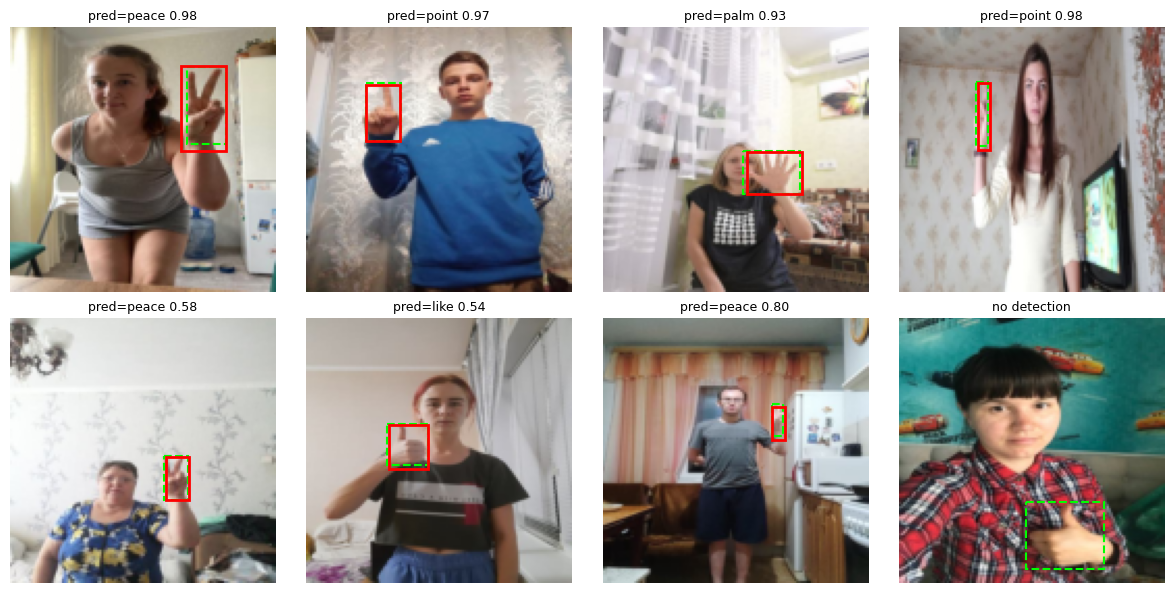

In [21]:
import matplotlib.patches as patches

val_ds = val_loader.dataset

fig, axes = plt.subplots(2, 4, figsize=(12, 6))
n_hits = 0
for i, ax in enumerate(tqdm(axes.flat, total=8, desc="rendering predictions", leave=False)):
    img, gt_box, gt_label = val_ds[i]
    det = detect_single_hand(model, img.unsqueeze(0).to(device), anchors_center_d, conf_thresh=0.5)

    ax.imshow(img.permute(1, 2, 0).numpy())
    gx1, gy1, gx2, gy2 = (gt_box * IMG_SIZE).tolist()
    ax.add_patch(patches.Rectangle((gx1, gy1), gx2 - gx1, gy2 - gy1, fill=False,
                                    edgecolor="lime", linewidth=1.5, linestyle="--"))
    if det is not None:
        n_hits += 1
        px1, py1, px2, py2 = det["box_px"].tolist()
        ax.add_patch(patches.Rectangle((px1, py1), px2 - px1, py2 - py1, fill=False,
                                        edgecolor="red", linewidth=2))
        ax.set_title(f"pred={det['label_name']} {det['score']:.2f}", fontsize=9)
    else:
        ax.set_title("no detection", fontsize=9)
    ax.axis("off")

fig.tight_layout()
out_path = os.path.join(MODELS_DIR, "demo_predictions.png")
fig.savefig(out_path, dpi=150)
print(f"detections above threshold: {n_hits}/8  (dashed green = ground truth, solid red = prediction)")
print(f"saved figure to {out_path}")

## 10 — ONNX Export (fixed shapes) → ESP-PPQ / ESP-DL

Static shapes throughout — ESP-PPQ (and ESP-DL) expect a fixed-shape graph, so
`dynamic_axes=None` and the legacy TorchScript-based exporter (`dynamo=False`) are used
deliberately here.

In [22]:
import copy


class ONNXWrapper(nn.Module):
    """Ensures ONNX export sees exactly two plain tensor outputs."""

    def __init__(self, m):
        super().__init__()
        self.m = m

    def forward(self, x):
        cls_out, loc_out = self.m(x)
        return cls_out, loc_out


def export_to_onnx(model, onnx_path: str = None):
    onnx_path = onnx_path or os.path.join(MODELS_DIR, "gesture_ssdlite.onnx")
    # deep-copy first -- wrapping `model` directly and calling .to("cpu") on the wrapper
    # moves the ORIGINAL model's parameters in place (nn.Module.to() mutates, it doesn't
    # clone), which would silently strand your live training-session `model` on CPU.
    export_model = ONNXWrapper(copy.deepcopy(model)).to("cpu").eval()
    dummy_input = torch.randn(1, 3, IMG_SIZE, IMG_SIZE)

    torch.onnx.export(
        export_model,
        dummy_input,
        onnx_path,
        opset_version=13,
        input_names=["input"],
        output_names=["cls_logits", "loc_preds"],
        do_constant_folding=True,
        dynamic_axes=None,      # fixed shapes required for ESP-PPQ / ESP-DL
        dynamo=False,            # legacy TorchScript exporter -> static-shape graph
    )
    print("exported:", onnx_path)
    return onnx_path, export_model, dummy_input


def verify_onnx(onnx_path: str, export_model: nn.Module, dummy_input: torch.Tensor):
    import onnx
    import onnxruntime as ort

    onnx_model = onnx.load(onnx_path)
    onnx.checker.check_model(onnx_model)
    print("onnx.checker passed")

    for t in onnx_model.graph.input:
        print("input :", t.name, [d.dim_value for d in t.type.tensor_type.shape.dim])
    for t in onnx_model.graph.output:
        print("output:", t.name, [d.dim_value for d in t.type.tensor_type.shape.dim])

    # numerically verify the ONNX graph matches the PyTorch model
    sess = ort.InferenceSession(onnx_path, providers=["CPUExecutionProvider"])
    ort_cls, ort_loc = sess.run(None, {"input": dummy_input.numpy()})
    with torch.no_grad():
        torch_cls, torch_loc = export_model(dummy_input)

    max_diff_cls = np.abs(ort_cls - torch_cls.numpy()).max()
    max_diff_loc = np.abs(ort_loc - torch_loc.numpy()).max()
    print(f"max abs diff -> cls: {max_diff_cls:.2e}   loc: {max_diff_loc:.2e}")
    assert np.allclose(ort_cls, torch_cls.numpy(), atol=1e-4)
    assert np.allclose(ort_loc, torch_loc.numpy(), atol=1e-4)
    print("ONNX <-> PyTorch numerical match OK")

    print(f"\n{onnx_path}: {os.path.getsize(onnx_path) / 1024:.1f} KB")

In [23]:
# export straight from the in-memory `model` (already holding the best checkpoint after
# Section 8). export_model is a CPU copy; `model` itself stays on `device`, untouched.
onnx_path, export_model, dummy_input = export_to_onnx(model)
verify_onnx(onnx_path, export_model, dummy_input)

exported: c:\Users\xared\Documents\30_PROJECTS\TinyGestureSSD\TinyGestureSSD\models_pretrained\gesture_ssdlite.onnx
onnx.checker passed
input : input [1, 3, 128, 128]
output: cls_logits [1, 128, 7]
output: loc_preds [1, 128, 4]
max abs diff -> cls: 5.72e-06   loc: 4.05e-06
ONNX <-> PyTorch numerical match OK

c:\Users\xared\Documents\30_PROJECTS\TinyGestureSSD\TinyGestureSSD\models_pretrained\gesture_ssdlite.onnx: 2136.9 KB


## 10b -- Quantization: PTQ then QAT, one session

Post-training quantization (PTQ) and quantization-aware fine-tuning (QAT) run back to back
below as a single continuous section, not two separate passes: PTQ produces `quant_ppq_graph`
and its own float32/PTQ-INT8 comparison figures first, then QAT fine-tunes that same graph
directly and gets an identical set of comparison figures against float32, plus a combined
three-way summary (float32 / PTQ-INT8 / QAT-INT8) at the end.

Requires ESP-PPQ installed once, outside the notebook:
```bash
pip install torch torchvision torchaudio --index-url https://download.pytorch.org/whl/cpu
pip install esp-ppq
```
(skip the torch/torchvision line if you already have a CUDA torch and want ESP-PPQ to use it)


### Next steps for on-device deployment

This notebook stops at a verified, static-shape ONNX graph, exported from the **best checkpoint by
validation macro-F1** (epoch printed in Section 8), trained on real HaGRID data with a pretrained
backbone, fitted anchors, and augmentation. To finish the pipeline:

1. **Quantize** `gesture_ssdlite.onnx` to INT8 with `esp_ppq.api.espdl_quantize_onnx` against a
   small calibration set of real frames from the HaGRID validation split used above.
2. **Update firmware constants** (`IMG_H/IMG_W/IMG_C`, buffer sizes) for 128×128×3 input, and
   replace a single-label argmax readout with logic that reads both heads (`cls_logits`,
   `loc_preds`) and applies the same threshold+argmax rule as `detect_single_hand` above.
3. **`WIDTH_MULT=1.0` is well past the ~100,000-param ESP32-class budget** the original
   anchor/head design was sized for (see `model.param_summary()` in Section 4 for the exact
   count). That's expected here — this notebook exists to test whether pretrained features fix
   convergence at all, before paying the cost of shrinking back down. If this run gets a val_f1
   worth keeping, the next step is either the KD notebook (distill this into a small from-scratch
   student) or structured pruning back toward width_mult≈0.35–0.5.
4. **If `SELECTION_METRIC` in Section 8 doesn't match your deployment priority** (e.g. you care
   more about never missing a gesture than about false positives), switch it to `"recall"` or
   `"precision"` and rerun training — everything downstream (best-checkpoint save, ONNX export)
   picks it up automatically.

In [24]:
# =============================================================================
# POST-QUANTIZATION ANALYSIS -- CELL 1 of 9
# Run this LAST in the notebook, after Section 10 (ONNX export) and after you've
# run the exported ONNX through your actual ESPDL quantization pipeline.
#
# This cell does NOT quantize anything itself -- it only computes the float32
# baseline (metrics, size, per-block activation sensitivity) that the real
# post-quantization numbers get compared against in Cell 2 onward.
#
# Depends on objects already in memory from earlier sections:
# model, val_loader, anchors_center_d, device, MODELS_DIR, evaluate,
# predict_batch_labels, CLASS_NAMES, NUM_CLASSES, IMG_SIZE
# =============================================================================

import os
import numpy as np
import torch
from sklearn.metrics import confusion_matrix


def state_dict_size_kb(m) -> float:
    import tempfile
    with tempfile.NamedTemporaryFile() as f:
        torch.save(m.state_dict(), f)
        return os.path.getsize(f.name) / 1024


@torch.no_grad()
def evaluate_with_predictions(model, loader, anchors_center, device, conf_thresh: float = 0.5):
    """Same metrics as `evaluate()`, but also returns per-sample predicted/true labels for a
    confusion matrix. A missed detection is encoded as label index NUM_CLASSES ("missed")."""
    model.eval()
    all_preds, all_gts = [], []
    for imgs, boxes, labels in loader:
        imgs_dev = imgs.to(device)
        preds = predict_batch_labels(model, imgs_dev, anchors_center, conf_thresh).cpu()
        preds = torch.where(preds == -1, torch.full_like(preds, NUM_CLASSES), preds)
        all_preds.append(preds)
        all_gts.append(labels)
    return torch.cat(all_preds).numpy(), torch.cat(all_gts).numpy()


def backbone_activation_sensitivity(fp32_model, X_sample: torch.Tensor):
    """Per-block estimate of how much INT8-level rounding would perturb this block's
    activations (min-max symmetric fake-quant at 8 bits). Diagnostic only -- flags which
    backbone blocks are the likely source if the real post-quantization run loses accuracy,
    it does not itself produce a quantized model."""
    results = []
    fp32_model = fp32_model.eval().cpu()
    with torch.no_grad():
        x = X_sample.cpu()
        for idx, block in enumerate(fp32_model.backbone):
            x = block(x)
            act = x.detach().numpy().astype(np.float32)
            act_max = np.max(np.abs(act)) + 1e-8
            scale = act_max / 127.0
            act_q = np.round(act / scale).clip(-128, 127) * scale
            mse = float(np.mean((act - act_q) ** 2))
            signal_power = float(np.mean(act ** 2))
            noise_power = mse + 1e-12
            sqnr = 10 * np.log10(signal_power / noise_power) if signal_power > 0 else 0.0
            results.append({"block": idx, "type": type(block).__name__, "mse": mse, "sqnr": sqnr})
    return results


# ---- float32 baseline -------------------------------------------------------
print("evaluating float32 baseline...")
metrics_fp32 = evaluate(model, val_loader, anchors_center_d, device)
preds_fp32, gts_fp32 = evaluate_with_predictions(model, val_loader, anchors_center_d, device)
size_fp32_kb = state_dict_size_kb(model)
layer_errors = backbone_activation_sensitivity(model, next(iter(val_loader))[0][:16])

print(f"\n{'Metric':<14}{'Float32':>10}")
for k, label in [("accuracy", "Accuracy"), ("precision", "Precision"),
                  ("recall", "Recall"), ("f1_macro", "F1 (macro)")]:
    print(f"{label:<14}{metrics_fp32[k]*100:>9.2f}%")
print(f"\nFloat32 size (state_dict): {size_fp32_kb:8.1f} KB")

evaluating float32 baseline...


validating:   0%|          | 0/7 [00:00<?, ?it/s]


Metric           Float32
Accuracy          79.68%
Precision         95.73%
Recall            79.82%
F1 (macro)        86.92%

Float32 size (state_dict):   2283.5 KB


In [25]:
# =============================================================================
# POST-QUANTIZATION ANALYSIS -- CELL 2 of 9
# Quantize Section 10's ONNX export into a real .espdl model using ESP-PPQ.
#
# Requires ESP-PPQ installed once, outside the notebook:
#   pip install torch torchvision torchaudio --index-url https://download.pytorch.org/whl/cpu
#   pip install esp-ppq
# (skip the torch/torchvision line if you already have a CUDA torch installed
# and want ESP-PPQ to use it -- esp-ppq works with either CPU or CUDA torch)
#
# ESP-DL only supports batch_size=1 on-device, and Section 10's ONNX export was
# built with a fixed batch size of 1 (dynamic_axes=None) -- so calibration and
# quantization here also run at batch_size=1 to match exactly what ships to the
# chip.
# =============================================================================

from torch.utils.data import DataLoader
from esp_ppq.api import espdl_quantize_onnx

ESPDL_TARGET = "esp32s3"     # quantization target chip
ESPDL_NUM_BITS = 8
ESPDL_CALIB_STEPS = min(200, len(val_loader.dataset))  # calibration passes, batch_size=1 each
ESPDL_DEVICE = "cuda" if torch.cuda.is_available() else "cpu"

ESPDL_MODEL_PATH = os.path.join(MODELS_DIR, "gesture_ssdlite.espdl")

# batch_size=1 to match the fixed-shape ONNX graph from Section 10; shuffle=False
# is required by ESP-PPQ -- calibration error stats need a stable pass order.
calib_loader = DataLoader(val_loader.dataset, batch_size=1, shuffle=False)


def collate_fn(batch):
    # calib_loader yields (imgs, boxes, labels) per step (default collate, batch_size=1) --
    # quantization only needs the image tensor.
    imgs, _boxes, _labels = batch
    return imgs.to(ESPDL_DEVICE)


print(f"quantizing to INT8 for target={ESPDL_TARGET} "
      f"({ESPDL_CALIB_STEPS} calibration steps, device={ESPDL_DEVICE})...")

quant_ppq_graph = espdl_quantize_onnx(
    onnx_import_file=onnx_path,                 # from Section 10
    espdl_export_file=ESPDL_MODEL_PATH,
    calib_dataloader=calib_loader,
    calib_steps=ESPDL_CALIB_STEPS,
    input_shape=[1, 3, IMG_SIZE, IMG_SIZE],
    inputs=None,
    target=ESPDL_TARGET,
    num_of_bits=ESPDL_NUM_BITS,
    collate_fn=collate_fn,
    device=ESPDL_DEVICE,
    error_report=True,
    skip_export=False,
    export_test_values=True,
    verbose=1,
)

size_int8_kb = os.path.getsize(ESPDL_MODEL_PATH) / 1024
print(f"\nexported: {ESPDL_MODEL_PATH}")
print(f"on-device size: {size_int8_kb:.1f} KB  ({size_fp32_kb / size_int8_kb:.2f}x smaller than float32)")


    ___________ ____        ____  ____  ____
   / ____/ ___// __ \      / __ \/ __ \/ __ \
  / __/  \__ \/ /_/ /_____/ /_/ / /_/ / / / /
 / /___ ___/ / ____/_____/ ____/ ____/ /_/ /
/_____//____/_/         /_/   /_/    \___\_\


quantizing to INT8 for target=esp32s3 (200 calibration steps, device=cuda)...
[23:49:21] ConvTranspose Decomposition Pass Running ... Finished.
[23:49:22] PPQ Quantization Fusion Pass Running ...       Finished.
[23:49:22] PPQ Quantize Simplify Pass Running ...         Finished.
[23:49:22] PPQ Parameter Quantization Pass Running ...    Finished.
[23:49:23] PPQ Runtime Calibration Pass Running ...       

Calibration Progress(Phase 2): 100%|██████████| 200/200 [00:14<00:00, 13.94it/s]


Finished.
[23:49:51] PPQ Quantization Alignment Pass Running ...    Finished.
[23:49:51] PPQ Passive Parameter Quantization Running ... Finished.
--------- Network Snapshot ---------
Num of Op:                    [85]
Num of Quantized Op:          [85]
Num of Variable:              [232]
Num of Quantized Var:         [232]
------- Quantization Snapshot ------
Num of Quant Config:          [324]
ACTIVATED:                    [87]
OVERLAPPED:                   [110]
PASSIVE:                      [123]
FP32:                         [4]
Network Quantization Finished.


Analysing Graphwise Quantization Error(Phrase 1):: 100%|██████████| 8/8 [00:00<00:00,  8.16it/s]
Analysing Graphwise Quantization Error(Phrase 2):: 100%|██████████| 8/8 [00:02<00:00,  3.53it/s]


Layer                                              | NOISE:SIGNAL POWER RATIO 
/m/backbone/backbone.10/conv/conv.2/Conv:          | ████████████████████ | 30.473%
/m/backbone/backbone.4/conv/conv.2/Conv:           | ██████████████████   | 27.445%
/m/backbone/backbone.6/conv/conv.2/Conv:           | ██████████████████   | 27.132%
/m/backbone/backbone.5/conv/conv.2/Conv:           | █████████████████    | 25.504%
/m/backbone/backbone.12/conv/conv.2/Conv:          | ███████████████      | 23.311%
/m/backbone/backbone.9/conv/conv.2/Conv:           | ███████████████      | 23.124%
/m/backbone/backbone.13/conv/conv.2/Conv:          | ██████████████       | 21.608%
/m/backbone/backbone.7/conv/conv.2/Conv:           | ██████████████       | 21.242%
/m/backbone/backbone.2/conv/conv.2/Conv:           | █████████████        | 19.782%
/m/backbone/backbone.11/conv/conv.2/Conv:          | █████████████        | 19.313%
/m/cls_head/depthwise/Conv:                        | ████████████         | 17.67

Analysing Layerwise quantization error:: 100%|██████████| 43/43 [00:11<00:00,  3.70it/s]


Layer                                              | NOISE:SIGNAL POWER RATIO 
/m/backbone/backbone.1/conv/conv.0/conv.0.0/Conv:  | ████████████████████ | 4.039%
/m/backbone/backbone.0/backbone.0.0/Conv:          | █████                | 0.967%
/m/backbone/backbone.3/conv/conv.1/conv.1.0/Conv:  | █                    | 0.281%
/m/backbone/backbone.11/conv/conv.1/conv.1.0/Conv: | █                    | 0.114%
/m/backbone/backbone.2/conv/conv.1/conv.1.0/Conv:  |                      | 0.064%
/m/backbone/backbone.5/conv/conv.1/conv.1.0/Conv:  |                      | 0.061%
/m/backbone/backbone.10/conv/conv.1/conv.1.0/Conv: |                      | 0.042%
/m/backbone/backbone.9/conv/conv.1/conv.1.0/Conv:  |                      | 0.040%
/m/backbone/backbone.13/conv/conv.1/conv.1.0/Conv: |                      | 0.036%
/m/loc_head/pointwise/Conv:                        |                      | 0.035%
/m/backbone/backbone.1/conv/conv.1/Conv:           |                      | 0.034%
/m/backb

In [26]:
# =============================================================================
# POST-QUANTIZATION ANALYSIS -- CELL 3 of 9
# Run the ACTUAL quantized graph from Cell 2 (quant_ppq_graph) over the validation
# set via ESP-PPQ's TorchExecutor. Per Espressif's docs, TorchExecutor output is
# numerically aligned with on-chip ESP-DL inference, so these are the real
# post-quantization numbers -- not a PyTorch-side approximation.
# =============================================================================

from esp_ppq.executor import TorchExecutor
import torch.nn.functional as F

executor = TorchExecutor(graph=quant_ppq_graph, device=ESPDL_DEVICE)


@torch.no_grad()
def evaluate_espdl(executor, dataset, anchors_center, device, conf_thresh: float = 0.5):
    """Batch_size=1 loop (ESP-DL/ESPDL graph only supports batch=1). Returns the same
    metrics dict shape as `evaluate()`, plus per-sample preds/labels for a confusion matrix
    (missed detection -> label index NUM_CLASSES)."""
    all_preds, all_gts = [], []
    for img, box, label in dataset:
        img_in = img.unsqueeze(0).to(device)
        outputs = executor(img_in)
        # output order matches the ONNX export names from Section 10: cls_logits, loc_preds
        cls_out, loc_out = outputs[0], outputs[1]

        probs = F.softmax(cls_out.float(), dim=-1)
        fg_probs = probs[..., 1:]
        best_score, best_cls = fg_probs.max(dim=-1)                 # (1, A)
        thresholded = best_score.masked_fill(best_score < conf_thresh, -1.0)
        top_score, top_anchor = thresholded.max(dim=-1)             # (1,)
        pred_cls = best_cls.gather(1, top_anchor.unsqueeze(1)).squeeze(1)
        pred_label = int(pred_cls.item()) if top_score.item() >= 0 else NUM_CLASSES

        all_preds.append(pred_label)
        all_gts.append(int(label))

    all_preds = np.array(all_preds)
    all_gts = np.array(all_gts)

    mask_valid = all_preds != NUM_CLASSES
    accuracy = accuracy_score(all_gts, all_preds)
    precision, recall, f1, _ = precision_recall_fscore_support(
        all_gts, all_preds, labels=list(range(NUM_CLASSES)), average="macro", zero_division=0)
    n_missed = int((all_preds == NUM_CLASSES).sum())
    return ({"accuracy": accuracy, "precision": precision, "recall": recall,
              "f1_macro": f1, "n_missed": n_missed, "n_total": len(all_gts)},
             all_preds, all_gts)


print(f"running quantized graph over {len(val_loader.dataset)} validation samples "
      f"(batch_size=1, this is real on-device-equivalent inference)...")

from sklearn.metrics import accuracy_score, precision_recall_fscore_support

metrics_int8, preds_int8, gts_int8 = evaluate_espdl(
    executor, val_loader.dataset, anchors_center_d, ESPDL_DEVICE)

print(f"\n{'Metric':<14}{'Float32':>10}{'INT8':>10}{'Delta':>10}")
for k, label in [("accuracy", "Accuracy"), ("precision", "Precision"),
                  ("recall", "Recall"), ("f1_macro", "F1 (macro)")]:
    a, b = metrics_fp32[k], metrics_int8[k]
    print(f"{label:<14}{a*100:>9.2f}%{b*100:>9.2f}%{(b-a)*100:>+9.2f}%")
print(f"\nFloat32 size:  {size_fp32_kb:8.1f} KB")
print(f"INT8 (.espdl): {size_int8_kb:8.1f} KB   ({size_fp32_kb / size_int8_kb:.2f}x smaller)")

running quantized graph over 433 validation samples (batch_size=1, this is real on-device-equivalent inference)...

Metric           Float32      INT8     Delta
Accuracy          79.68%    70.44%    -9.24%
Precision         95.73%    94.82%    -0.91%
Recall            79.82%    70.59%    -9.23%
F1 (macro)        86.92%    80.80%    -6.12%

Float32 size:    2283.5 KB
INT8 (.espdl):    692.7 KB   (3.30x smaller)


In [27]:
# =============================================================================
# POST-QUANTIZATION ANALYSIS -- CELL 4 of 9
# Shared paper-style plotting setup. All figures below save to MODELS_DIR at
# 300 dpi, single subplot each, IEEE-column-width sized.
# =============================================================================

import matplotlib.pyplot as plt

PAPER_STYLE = {
    "figure.facecolor": "white",
    "axes.facecolor": "white",
    "axes.edgecolor": "#333333",
    "axes.labelcolor": "#111111",
    "axes.titlesize": 12,
    "axes.labelsize": 11,
    "xtick.color": "#333333",
    "ytick.color": "#333333",
    "xtick.labelsize": 9,
    "ytick.labelsize": 9,
    "legend.fontsize": 9,
    "font.family": "sans-serif",
    "font.sans-serif": ["Arial", "Helvetica", "DejaVu Sans"],
    "grid.color": "#dddddd",
    "grid.linewidth": 0.6,
    "savefig.dpi": 300,
    "savefig.bbox": "tight",
}
plt.rcParams.update(PAPER_STYLE)

# colorblind-safe two-tone palette (Wong 2011)
C_FP32 = "#0072B2"    # blue
C_INT8 = "#D55E00"    # vermillion
C_ACCENT = "#009E73"  # bluish green


def save_fig(fig, name):
    path = os.path.join(MODELS_DIR, name)
    fig.savefig(path)
    print(f"saved: {path}")

saved: c:\Users\xared\Documents\30_PROJECTS\TinyGestureSSD\TinyGestureSSD\models_pretrained\fig1_metrics_fp32_vs_int8.png


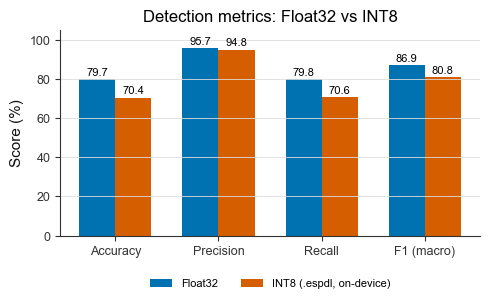

In [28]:
# =============================================================================
# POST-QUANTIZATION ANALYSIS -- CELL 5 of 9
# Figure 1: Accuracy / Precision / Recall / F1, float32 vs INT8 (real, on-device)
# =============================================================================

import numpy as np

fig, ax = plt.subplots(figsize=(5.0, 3.2))
labels = ["Accuracy", "Precision", "Recall", "F1 (macro)"]
keys = ["accuracy", "precision", "recall", "f1_macro"]
fp32_vals = [metrics_fp32[k] * 100 for k in keys]
int8_vals = [metrics_int8[k] * 100 for k in keys]

x = np.arange(len(labels))
w = 0.35
b1 = ax.bar(x - w / 2, fp32_vals, w, label="Float32", color=C_FP32)
b2 = ax.bar(x + w / 2, int8_vals, w, label="INT8 (.espdl, on-device)", color=C_INT8)

for bars in (b1, b2):
    for bar in bars:
        h = bar.get_height()
        ax.text(bar.get_x() + bar.get_width() / 2, h + 1, f"{h:.1f}", ha="center",
                va="bottom", fontsize=8)

ax.set_ylim(0, 105)
ax.set_ylabel("Score (%)")
ax.set_xticks(x)
ax.set_xticklabels(labels)
ax.set_title("Detection metrics: Float32 vs INT8")
ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.16), ncol=4, fontsize=8, frameon=False)
ax.grid(axis="y")
ax.spines[["top", "right"]].set_visible(False)
fig.tight_layout()
save_fig(fig, "fig1_metrics_fp32_vs_int8.png")
plt.show()

saved: c:\Users\xared\Documents\30_PROJECTS\TinyGestureSSD\TinyGestureSSD\models_pretrained\fig2_model_size.png


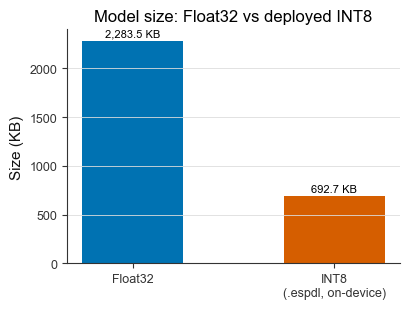

In [29]:
# =============================================================================
# POST-QUANTIZATION ANALYSIS -- CELL 6 of 9
# Figure 2: model size, float32 vs the real on-device INT8/.espdl size
# =============================================================================

fig, ax = plt.subplots(figsize=(4.2, 3.2))
sizes = [size_fp32_kb, size_int8_kb]
tick_labels = ["Float32", "INT8\n(.espdl, on-device)"]
colors = [C_FP32, C_INT8]

bars = ax.bar(tick_labels, sizes, color=colors, width=0.5)
for bar, val in zip(bars, sizes):
    ax.text(bar.get_x() + bar.get_width() / 2, bar.get_height() + max(sizes) * 0.01,
            f"{val:,.1f} KB", ha="center", va="bottom", fontsize=8)
ax.set_ylabel("Size (KB)")
ax.set_title("Model size: Float32 vs deployed INT8")
ax.grid(axis="y")
ax.spines[["top", "right"]].set_visible(False)
fig.tight_layout()
save_fig(fig, "fig2_model_size.png")
plt.show()

saved: c:\Users\xared\Documents\30_PROJECTS\TinyGestureSSD\TinyGestureSSD\models_pretrained\fig3_confusion_fp32.png


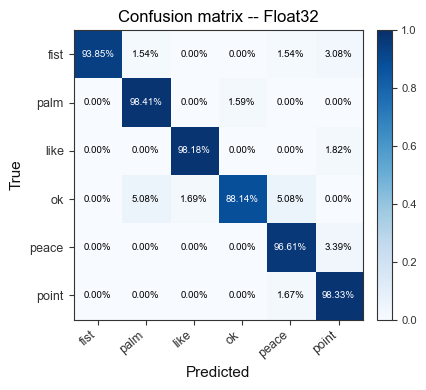

saved: c:\Users\xared\Documents\30_PROJECTS\TinyGestureSSD\TinyGestureSSD\models_pretrained\fig4_confusion_int8.png


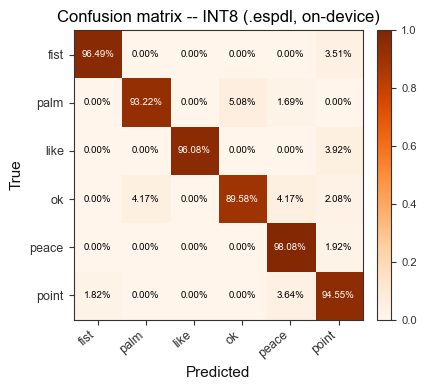

In [30]:
# =============================================================================
# POST-QUANTIZATION ANALYSIS -- CELL 7 of 9
# Figures 3 & 4: confusion matrices, float32 vs the real on-device INT8 model
# =============================================================================

from sklearn.metrics import confusion_matrix

cm_labels = CLASS_NAMES


def plot_confusion(preds, gts, title, filename, cmap):
    cm = confusion_matrix(gts, preds, labels=list(range(NUM_CLASSES)), normalize="true")
    fig, ax = plt.subplots(figsize=(4.6, 4.0))
    im = ax.imshow(cm, cmap=cmap, vmin=0, vmax=1)
    ax.set_xticks(range(len(cm_labels)))
    ax.set_yticks(range(len(cm_labels)))
    ax.set_xticklabels(cm_labels, rotation=40, ha="right")
    ax.set_yticklabels(cm_labels)
    ax.set_xlabel("Predicted")
    ax.set_ylabel("True")
    ax.set_title(title)
    for i in range(cm.shape[0]):
        for j in range(cm.shape[1]):
            v = cm[i, j]
            ax.text(j, i, f"{v*100:.2f}%", ha="center", va="center",
                    color="white" if v > 0.5 else "black", fontsize=7)
    cbar = fig.colorbar(im, ax=ax, fraction=0.046, pad=0.04)
    cbar.ax.tick_params(labelsize=8)
    fig.tight_layout()
    save_fig(fig, filename)
    plt.show()


plot_confusion(preds_fp32, gts_fp32, "Confusion matrix -- Float32",
               "fig3_confusion_fp32.png", "Blues")
plot_confusion(preds_int8, gts_int8, "Confusion matrix -- INT8 (.espdl, on-device)",
               "fig4_confusion_int8.png", "Oranges")

saved: c:\Users\xared\Documents\30_PROJECTS\TinyGestureSSD\TinyGestureSSD\models_pretrained\fig5_backbone_sqnr.png


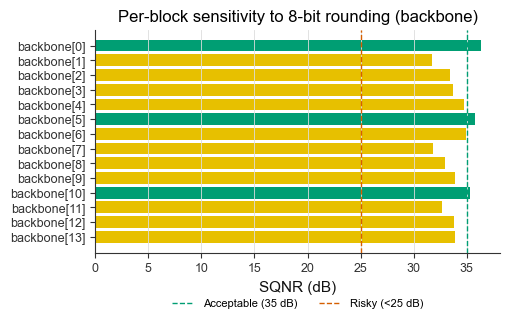

In [31]:
# =============================================================================
# POST-QUANTIZATION ANALYSIS -- CELL 8 of 9
# Figure 5: per-block activation SQNR (diagnostic, backbone sensitivity to
# 8-bit rounding -- from Cell 1, not the real deployed model)
# =============================================================================

fig, ax = plt.subplots(figsize=(5.2, 3.4))
block_names = [f"backbone[{r['block']}]" for r in layer_errors]
sqnrs = [min(r["sqnr"], 60) for r in layer_errors]
colors_sqnr = [C_ACCENT if s >= 35 else "#E7C000" if s >= 25 else C_INT8 for s in sqnrs]

ax.barh(block_names, sqnrs, color=colors_sqnr)
ax.axvline(35, color=C_ACCENT, linestyle="--", linewidth=1, label="Acceptable (35 dB)")
ax.axvline(25, color=C_INT8, linestyle="--", linewidth=1, label="Risky (<25 dB)")
ax.set_xlabel("SQNR (dB)")
ax.set_title("Per-block sensitivity to 8-bit rounding (backbone)")
ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.16), ncol=4, fontsize=8, frameon=False)
ax.grid(axis="x")
ax.spines[["top", "right"]].set_visible(False)
ax.invert_yaxis()
fig.tight_layout()
save_fig(fig, "fig5_backbone_sqnr.png")
plt.show()

saved: c:\Users\xared\Documents\30_PROJECTS\TinyGestureSSD\TinyGestureSSD\models_pretrained\fig6_backbone_mse.png


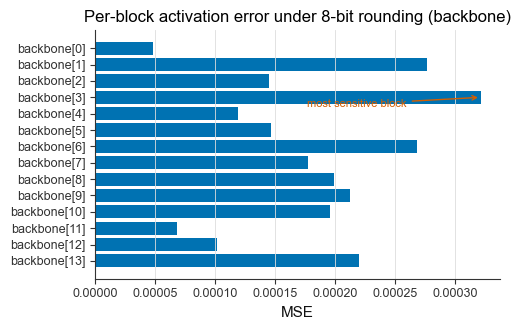

In [32]:
# =============================================================================
# POST-QUANTIZATION ANALYSIS -- CELL 9 of 9
# Figure 6: per-block activation MSE (diagnostic, same source as Figure 5)
# =============================================================================

fig, ax = plt.subplots(figsize=(5.2, 3.4))
mses = [r["mse"] for r in layer_errors]
ax.barh(block_names, mses, color=C_FP32)
ax.set_xlabel("MSE")
ax.set_title("Per-block activation error under 8-bit rounding (backbone)")
ax.grid(axis="x")
ax.spines[["top", "right"]].set_visible(False)
ax.invert_yaxis()
worst = int(np.argmax(mses))
ax.annotate("most sensitive block", xy=(mses[worst], worst),
            xytext=(mses[worst] * 0.55, worst + 0.6),
            fontsize=8, color=C_INT8,
            arrowprops=dict(arrowstyle="->", color=C_INT8))
fig.tight_layout()
save_fig(fig, "fig6_backbone_mse.png")
plt.show()

### QAT -- continuing the same quantization session

Fine-tunes the PTQ-quantized graph from Section 10's post-quantization analysis directly
(ESP-PPQ `TrainableGraph` + `forward_with_gradient`, the same mechanism ESP-DL's own QAT
examples use), then compares Float32 / PTQ-INT8 / QAT-INT8. This mirrors
`TinyGestureSSD_kd.ipynb` Section 11 exactly -- same `QATTrainer`, same per-sample
gradient-accumulation workaround for the batch=1 ONNX export, same figure/table conventions --
adapted to this notebook's single model (there is no teacher/student split here, so the
comparison is a 3-way fp32 / PTQ-INT8 / QAT-INT8 instead of kd's 4-way).

Before spending `QAT_EPOCHS` of fine-tuning, this checks for a cached result
(`models_pretrained/qat_result_cache.json` + `qat_preds.npy` / `qat_gts.npy`) and loads that
instead of retraining, the same "carry on from the best model instead of redoing work"
pattern used for Section 8's checkpoint. Set `FORCE_RETRAIN_QAT = True` below to force a
fresh QAT run regardless of what's cached.


In [33]:
from esp_ppq.IR import TrainableGraph
from esp_ppq.core import TargetPlatform
import esp_ppq.lib as PFL
from esp_ppq.parser import NativeExporter

QAT_EPOCHS = 10
QAT_LR = 1e-6
QAT_MOMENTUM = 0.937
QAT_WEIGHT_DECAY = 5e-4


class QATTrainer:
    """Adaptation of ESP-DL's own QAT Trainer (quantize_yolo11n-pose/trainer.py) to this
    project's MultiBoxLoss + anchor-matching pipeline instead of the Ultralytics pose loss.
    Identical to the QATTrainer in TinyGestureSSD_kd.ipynb Section 11 -- copied rather than
    imported since these are standalone notebooks.

    NOTE ON BATCH SIZE: `graph` comes from `espdl_quantize_onnx`, which quantized a
    statically-shaped ONNX export (batch=1 baked into every Reshape op -- Section 10 uses
    `dynamic_axes=None`, which ESP-DL requires). `forward_with_gradient` on this graph only
    accepts batch=1 input; feeding it a BATCH_SIZE=64 tensor throws a Reshape shape mismatch.

    QATTrainer therefore runs one sample at a time through the graph and accumulates
    gradients over `accum_steps` samples before each optimizer.step(), so the effective
    batch size and the number of optimizer steps per epoch match a real batch=accum_steps
    run -- only the forward/backward calls are serialized per-sample instead of batched.
    """

    def __init__(self, graph, device: str, accum_steps: int = BATCH_SIZE):
        self._epoch = 0
        self._device = device
        self._executor = TorchExecutor(graph, device=device)
        self._training_graph = TrainableGraph(graph)
        self.graph = graph
        self.accum_steps = accum_steps

        for tensor in self._training_graph.parameters():
            tensor.requires_grad = True

        self._optimizer = torch.optim.SGD(
            params=[{"params": self._training_graph.parameters()}],
            lr=QAT_LR, momentum=QAT_MOMENTUM, weight_decay=QAT_WEIGHT_DECAY)
        self.criterion = MultiBoxLoss().to(device)

    def _step(self, imgs, boxes, labels, anchors_center, anchors_corner):
        imgs = imgs.to(self._device)
        boxes = boxes.to(self._device)
        labels = labels.to(self._device)

        graph_outputs = self._executor.forward_with_gradient(imgs)
        cls_preds, loc_preds = graph_outputs[0], graph_outputs[1]   # matches ONNX output order

        cls_t, loc_t, pos_m, ign_m = match_anchors_to_targets(boxes, labels, anchors_center, anchors_corner)
        total_loss, loc_loss, cls_loss = self.criterion(cls_preds, loc_preds, cls_t, loc_t, pos_m, ign_m)

        (total_loss / self.accum_steps).backward()
        return total_loss.item()

    def epoch(self, loader, anchors_center, anchors_corner):
        running = 0.0
        n = len(loader)
        self._training_graph.zero_grad()
        for i, (imgs, boxes, labels) in enumerate(
                tqdm(loader, desc=f"QAT epoch {self._epoch + 1}/{QAT_EPOCHS}", leave=False), start=1):
            running += self._step(imgs, boxes, labels, anchors_center, anchors_corner)
            if i % self.accum_steps == 0 or i == n:
                torch.nn.utils.clip_grad_norm_(self._training_graph.parameters(), max_norm=5.0)
                self._optimizer.step()
                self._training_graph.zero_grad()
        self._epoch += 1
        return running / n

    @torch.no_grad()
    def eval(self, val_dataset, anchors_center):
        return evaluate_espdl(self._executor, val_dataset, anchors_center, self._device)

    def save(self, espdl_path: str, native_path: str):
        PFL.Exporter(platform=TargetPlatform.ESPDL_INT8).export(file_path=espdl_path, graph=self.graph)
        NativeExporter().export(file_path=native_path, graph=self.graph)


In [34]:
# =============================================================================
# QAT training loop, with result caching so a rerun doesn't redo QAT_EPOCHS of
# fine-tuning if a previous run already produced a best checkpoint. Same idea as
# Section 8's FORCE_RETRAIN checkpoint-resume, just for the QAT stage.
# =============================================================================

from torch.utils.data import DataLoader
import numpy as np
import json

FORCE_RETRAIN_QAT = False   # set True to always re-run QAT_EPOCHS even if a cached result exists

QAT_ACCUM_STEPS = BATCH_SIZE
QAT_ESPDL_PATH = os.path.join(MODELS_DIR, "gesture_ssdlite_qat.espdl")
QAT_NATIVE_PATH = os.path.join(MODELS_DIR, "gesture_ssdlite_qat.native")
QAT_CACHE_PATH = os.path.join(MODELS_DIR, "qat_result_cache.json")
QAT_PREDS_PATH = os.path.join(MODELS_DIR, "qat_preds.npy")
QAT_GTS_PATH = os.path.join(MODELS_DIR, "qat_gts.npy")

if not FORCE_RETRAIN_QAT and os.path.exists(QAT_CACHE_PATH) and os.path.exists(QAT_PREDS_PATH):
    print(f"found cached QAT result: {QAT_CACHE_PATH}")
    print("loading instead of retraining (set FORCE_RETRAIN_QAT = True above to force a fresh run)")
    with open(QAT_CACHE_PATH) as f:
        _cache = json.load(f)
    best_qat_f1 = _cache["best_qat_f1"]
    best_qat_epoch = _cache["best_qat_epoch"]
    best_qat_metrics = _cache["best_qat_metrics"]
    size_qat_kb = _cache["size_qat_kb"]
    best_qat_preds = np.load(QAT_PREDS_PATH)
    best_qat_gts = np.load(QAT_GTS_PATH)
    print(f"loaded. best QAT epoch={best_qat_epoch}  f1_macro={best_qat_f1:.4f}  size={size_qat_kb:.1f} KB")
else:
    qat_loader = DataLoader(train_loader.dataset, batch_size=1, shuffle=True)
    qat_trainer = QATTrainer(quant_ppq_graph, device=ESPDL_DEVICE, accum_steps=QAT_ACCUM_STEPS)

    best_qat_f1 = metrics_int8["f1_macro"]
    best_qat_epoch = 0
    # default to the PTQ result -- keeps downstream cells well-defined even if QAT never
    # beats PTQ (the two bars will just come out identical, which is itself a valid,
    # reportable result, not a broken run).
    best_qat_metrics, best_qat_preds, best_qat_gts = metrics_int8, preds_int8, gts_int8
    print(f"pre-QAT (PTQ) baseline: f1_macro={best_qat_f1:.4f}")

    for epoch in range(1, QAT_EPOCHS + 1):
        train_loss = qat_trainer.epoch(qat_loader, anchors_center_d, anchors_corner_d)
        epoch_metrics, epoch_preds, epoch_gts = qat_trainer.eval(val_loader.dataset, anchors_center_d)

        is_best = epoch_metrics["f1_macro"] > best_qat_f1
        if is_best:
            best_qat_f1 = epoch_metrics["f1_macro"]
            best_qat_epoch = epoch
            best_qat_metrics, best_qat_preds, best_qat_gts = epoch_metrics, epoch_preds, epoch_gts
            qat_trainer.save(QAT_ESPDL_PATH, QAT_NATIVE_PATH)

        print(f"QAT epoch {epoch}/{QAT_EPOCHS}  train_loss={train_loss:.4f}  "
              f"val_f1={epoch_metrics['f1_macro']:.4f}  val_acc={epoch_metrics['accuracy']:.4f}"
              f"{'  <-- best so far, saved' if is_best else ''}")

    print(f"\nbest QAT checkpoint: epoch {best_qat_epoch}  f1_macro={best_qat_f1:.4f}")
    if best_qat_epoch == 0:
        print("QAT never beat the plain PTQ baseline -- no .espdl/.native was saved this run. "
              "The comparison cells below will show PTQ and QAT as identical bars, since "
              "best_qat_* falls back to the PTQ result.")

    if best_qat_epoch > 0 and os.path.exists(QAT_ESPDL_PATH):
        size_qat_kb = os.path.getsize(QAT_ESPDL_PATH) / 1024
    else:
        size_qat_kb = size_int8_kb

    # cache to disk so the next run can skip straight to the comparison cells
    with open(QAT_CACHE_PATH, "w") as f:
        json.dump({"best_qat_f1": best_qat_f1, "best_qat_epoch": best_qat_epoch,
                    "best_qat_metrics": {k: float(v) for k, v in best_qat_metrics.items()},
                    "size_qat_kb": size_qat_kb}, f, indent=2)
    np.save(QAT_PREDS_PATH, np.asarray(best_qat_preds))
    np.save(QAT_GTS_PATH, np.asarray(best_qat_gts))
    print(f"cached QAT result -> {QAT_CACHE_PATH}")


pre-QAT (PTQ) baseline: f1_macro=0.8080


QAT epoch 1/10:   0%|          | 0/3906 [00:00<?, ?it/s]

[INFO][ESPDL][2026-08-16 00:11:45]:  Skip /m/Constant_output_0 because it's not exportable
[INFO][ESPDL][2026-08-16 00:11:45]:  Skip /m/Constant_2_output_0 because it's not exportable
[INFO][ESPDL][2026-08-16 00:11:45]:  Skip /m/Constant_1_output_0 because it's not exportable
[INFO][ESPDL][2026-08-16 00:11:45]:  Skip /m/Constant_3_output_0 because it's not exportable
[INFO][ESPDL][2026-08-16 00:11:45]:  Skip /m/Constant_output_0 because it's not exportable
[INFO][ESPDL][2026-08-16 00:11:45]:  Skip /m/Constant_2_output_0 because it's not exportable
[INFO][ESPDL][2026-08-16 00:11:45]:  Skip /m/Constant_1_output_0 because it's not exportable
[INFO][ESPDL][2026-08-16 00:11:45]:  Skip /m/Constant_3_output_0 because it's not exportable
[INFO][ESPDL][2026-08-16 00:11:45]:  Skip /m/Constant_output_0 because it's not exportable
[INFO][ESPDL][2026-08-16 00:11:45]:  Skip /m/Constant_2_output_0 because it's not exportable
[INFO][ESPDL][2026-08-16 00:11:45]:  Skip /m/Constant_1_output_0 because it'

QAT epoch 2/10:   0%|          | 0/3906 [00:00<?, ?it/s]

[INFO][ESPDL][2026-08-16 00:32:16]:  Skip /m/Constant_output_0 because it's not exportable
[INFO][ESPDL][2026-08-16 00:32:16]:  Skip /m/Constant_2_output_0 because it's not exportable
[INFO][ESPDL][2026-08-16 00:32:16]:  Skip /m/Constant_1_output_0 because it's not exportable
[INFO][ESPDL][2026-08-16 00:32:16]:  Skip /m/Constant_3_output_0 because it's not exportable
[INFO][ESPDL][2026-08-16 00:32:16]:  Skip /m/Constant_output_0 because it's not exportable
[INFO][ESPDL][2026-08-16 00:32:16]:  Skip /m/Constant_2_output_0 because it's not exportable
[INFO][ESPDL][2026-08-16 00:32:16]:  Skip /m/Constant_1_output_0 because it's not exportable
[INFO][ESPDL][2026-08-16 00:32:16]:  Skip /m/Constant_3_output_0 because it's not exportable
[INFO][ESPDL][2026-08-16 00:32:16]:  Skip /m/Constant_output_0 because it's not exportable
[INFO][ESPDL][2026-08-16 00:32:16]:  Skip /m/Constant_2_output_0 because it's not exportable
[INFO][ESPDL][2026-08-16 00:32:16]:  Skip /m/Constant_1_output_0 because it'

...

QAT epoch 8/10  train_loss=1.6886  val_f1=0.8181  val_acc=0.7182


QAT epoch 9/10:   0%|          | 0/3906 [00:00<?, ?it/s]

[INFO][ESPDL][2026-08-16 03:07:55]:  Skip /m/Constant_output_0 because it's not exportable
[INFO][ESPDL][2026-08-16 03:07:55]:  Skip /m/Constant_2_output_0 because it's not exportable
[INFO][ESPDL][2026-08-16 03:07:55]:  Skip /m/Constant_1_output_0 because it's not exportable
[INFO][ESPDL][2026-08-16 03:07:55]:  Skip /m/Constant_3_output_0 because it's not exportable
[INFO][ESPDL][2026-08-16 03:07:56]:  Skip /m/Constant_output_0 because it's not exportable
[INFO][ESPDL][2026-08-16 03:07:56]:  Skip /m/Constant_2_output_0 because it's not exportable
[INFO][ESPDL][2026-08-16 03:07:56]:  Skip /m/Constant_1_output_0 because it's not exportable
[INFO][ESPDL][2026-08-16 03:07:56]:  Skip /m/Constant_3_output_0 because it's not exportable
[INFO][ESPDL][2026-08-16 03:07:56]:  Skip /m/Constant_output_0 because it's not exportable
[INFO][ESPDL][2026-08-16 03:07:56]:  Skip /m/Constant_2_output_0 because it's not exportable
[INFO][ESPDL][2026-08-16 03:07:56]:  Skip /m/Constant_1_output_0 because it'

QAT epoch 10/10:   0%|          | 0/3906 [00:00<?, ?it/s]

[INFO][ESPDL][2026-08-16 03:28:28]:  Skip /m/Constant_output_0 because it's not exportable
[INFO][ESPDL][2026-08-16 03:28:28]:  Skip /m/Constant_2_output_0 because it's not exportable
[INFO][ESPDL][2026-08-16 03:28:28]:  Skip /m/Constant_1_output_0 because it's not exportable
[INFO][ESPDL][2026-08-16 03:28:28]:  Skip /m/Constant_3_output_0 because it's not exportable
[INFO][ESPDL][2026-08-16 03:28:28]:  Skip /m/Constant_output_0 because it's not exportable
[INFO][ESPDL][2026-08-16 03:28:28]:  Skip /m/Constant_2_output_0 because it's not exportable
[INFO][ESPDL][2026-08-16 03:28:28]:  Skip /m/Constant_1_output_0 because it's not exportable
[INFO][ESPDL][2026-08-16 03:28:28]:  Skip /m/Constant_3_output_0 because it's not exportable
[INFO][ESPDL][2026-08-16 03:28:28]:  Skip /m/Constant_output_0 because it's not exportable
[INFO][ESPDL][2026-08-16 03:28:28]:  Skip /m/Constant_2_output_0 because it's not exportable
[INFO][ESPDL][2026-08-16 03:28:28]:  Skip /m/Constant_1_output_0 because it'

### Full stat parity: QAT gets the same pairwise figures PTQ got

`fig7`/`fig8` above mirror `fig1`/`fig2` from the PTQ analysis exactly (Float32 vs the
quantized model, metrics then size), just swapped to the QAT-INT8 model. The QAT confusion
matrix below (`fig9`) already existed and mirrors `fig3`/`fig4`'s pairing the same way.

Not mirrored: `fig5`/`fig6` (per-block SQNR/MSE) are diagnostics computed on the **float32**
backbone's activations under simulated 8-bit rounding -- they measure a property of the fp32
model, not of a specific quantized model, so they're identical for PTQ and QAT by construction
(re-running them here would just reproduce fig5/fig6, not add information). If per-block
QAT-specific diagnostics are wanted later (e.g. per-layer weight drift from the PTQ starting
point), that's a different measurement than what fig5/fig6 compute -- flag it if useful.


saved: c:\Users\xared\Documents\30_PROJECTS\TinyGestureSSD\TinyGestureSSD\models_pretrained\fig7_metrics_fp32_vs_qat.png


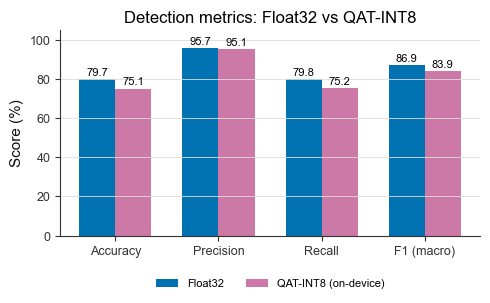

In [35]:
# =============================================================================
# Figure 7: Accuracy / Precision / Recall / F1 -- Float32 vs QAT-INT8
# (pairwise, mirrors Figure 1's Float32-vs-PTQ-INT8 structure exactly, so PTQ and QAT get
# the same individual-figure treatment -- not just the 3-way summary further down)
# =============================================================================

C_QAT = "#CC79A7"  # reddish purple, next in the same colorblind-safe (Okabe-Ito) family
                    # as C_FP32/C_INT8 above

fig, ax = plt.subplots(figsize=(5.0, 3.2))
labels = ["Accuracy", "Precision", "Recall", "F1 (macro)"]
keys = ["accuracy", "precision", "recall", "f1_macro"]
fp32_vals = [metrics_fp32[k] * 100 for k in keys]
qat_vals = [best_qat_metrics[k] * 100 for k in keys]

x = np.arange(len(labels))
w = 0.35
b1 = ax.bar(x - w / 2, fp32_vals, w, label="Float32", color=C_FP32)
b2 = ax.bar(x + w / 2, qat_vals, w, label="QAT-INT8 (on-device)", color=C_QAT)

for bars in (b1, b2):
    for bar in bars:
        h = bar.get_height()
        ax.text(bar.get_x() + bar.get_width() / 2, h + 1, f"{h:.1f}", ha="center",
                va="bottom", fontsize=8)

ax.set_ylim(0, 105)
ax.set_ylabel("Score (%)")
ax.set_xticks(x)
ax.set_xticklabels(labels)
ax.set_title("Detection metrics: Float32 vs QAT-INT8")
ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.16), ncol=4, fontsize=8, frameon=False)
ax.grid(axis="y")
ax.spines[["top", "right"]].set_visible(False)
fig.tight_layout()
save_fig(fig, "fig7_metrics_fp32_vs_qat.png")
plt.show()


saved: c:\Users\xared\Documents\30_PROJECTS\TinyGestureSSD\TinyGestureSSD\models_pretrained\fig8_model_size_fp32_vs_qat.png


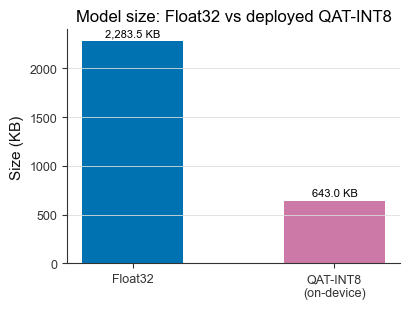

In [36]:
# =============================================================================
# Figure 8: model size -- Float32 vs QAT-INT8 (pairwise, mirrors Figure 2)
# =============================================================================

fig, ax = plt.subplots(figsize=(4.2, 3.2))
sizes = [size_fp32_kb, size_qat_kb]
tick_labels = ["Float32", "QAT-INT8\n(on-device)"]
colors = [C_FP32, C_QAT]

bars = ax.bar(tick_labels, sizes, color=colors, width=0.5)
for bar, val in zip(bars, sizes):
    ax.text(bar.get_x() + bar.get_width() / 2, bar.get_height() + max(sizes) * 0.01,
            f"{val:,.1f} KB", ha="center", va="bottom", fontsize=8)
ax.set_ylabel("Size (KB)")
ax.set_title("Model size: Float32 vs deployed QAT-INT8")
ax.grid(axis="y")
ax.spines[["top", "right"]].set_visible(False)
fig.tight_layout()
save_fig(fig, "fig8_model_size_fp32_vs_qat.png")
plt.show()


### 11a -- Float32 / PTQ-INT8 / QAT-INT8 comparison

Same figures as Section 10's post-quantization analysis (`fig1`-`fig6`), extended with the
QAT-INT8 result (`best_qat_metrics`, `best_qat_preds`, `best_qat_gts`, `size_qat_kb` from the
cell above). Three-way comparison since this notebook has no teacher/student split: this
model's own fp32 -> PTQ-INT8 -> QAT-INT8.


saved: c:\Users\xared\Documents\30_PROJECTS\TinyGestureSSD\TinyGestureSSD\models_pretrained\fig11_metrics_fp32_vs_ptq_vs_qat.png


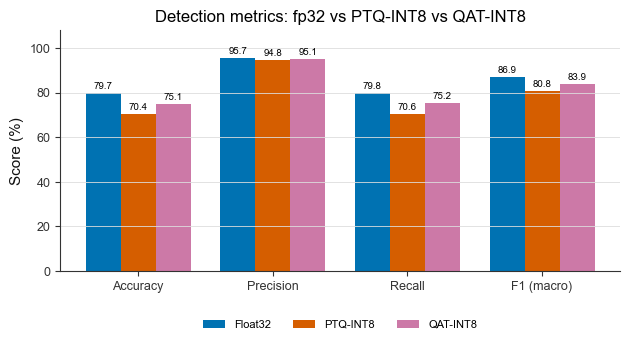

In [37]:
# =============================================================================
# Figure 11: Accuracy / Precision / Recall / F1 -- fp32 vs PTQ-INT8 vs QAT-INT8
# =============================================================================

C_QAT = "#CC79A7"  # reddish purple, next in the same colorblind-safe (Okabe-Ito) family
                    # as C_FP32/C_INT8 above

fig, ax = plt.subplots(figsize=(6.4, 3.6))
labels = ["Accuracy", "Precision", "Recall", "F1 (macro)"]
keys = ["accuracy", "precision", "recall", "f1_macro"]
fp32_vals = [metrics_fp32[k] * 100 for k in keys]
ptq_vals = [metrics_int8[k] * 100 for k in keys]
qat_vals = [best_qat_metrics[k] * 100 for k in keys]

x = np.arange(len(labels))
w = 0.26
b1 = ax.bar(x - w, fp32_vals, w, label="Float32", color=C_FP32)
b2 = ax.bar(x, ptq_vals, w, label="PTQ-INT8", color=C_INT8)
b3 = ax.bar(x + w, qat_vals, w, label="QAT-INT8", color=C_QAT)

for bars in (b1, b2, b3):
    for bar in bars:
        h = bar.get_height()
        ax.text(bar.get_x() + bar.get_width() / 2, h + 1, f"{h:.1f}", ha="center",
                va="bottom", fontsize=7)

ax.set_ylim(0, 108)
ax.set_ylabel("Score (%)")
ax.set_xticks(x)
ax.set_xticklabels(labels)
ax.set_title("Detection metrics: fp32 vs PTQ-INT8 vs QAT-INT8")
ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.16), ncol=4, fontsize=8, frameon=False)
ax.grid(axis="y")
ax.spines[["top", "right"]].set_visible(False)
fig.tight_layout()
save_fig(fig, "fig11_metrics_fp32_vs_ptq_vs_qat.png")
plt.show()


saved: c:\Users\xared\Documents\30_PROJECTS\TinyGestureSSD\TinyGestureSSD\models_pretrained\fig12_model_size_fp32_vs_ptq_vs_qat.png


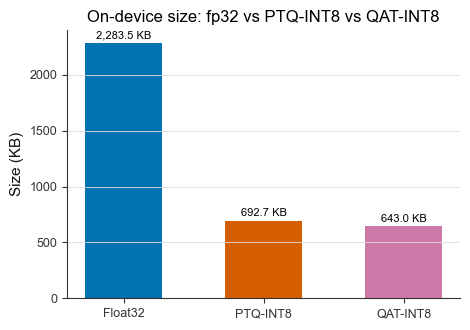

In [38]:
# =============================================================================
# Figure 12: on-device size -- fp32 vs PTQ-INT8 vs QAT-INT8
# (PTQ and QAT share the same op graph and INT8 byte layout, so these two bars are expected
# to be equal or near-equal -- QAT changes weight VALUES, not model SIZE)
# =============================================================================

fig, ax = plt.subplots(figsize=(4.8, 3.4))
sizes = [size_fp32_kb, size_int8_kb, size_qat_kb]
tick_labels = ["Float32", "PTQ-INT8", "QAT-INT8"]
colors = [C_FP32, C_INT8, C_QAT]

bars = ax.bar(tick_labels, sizes, color=colors, width=0.55)
for bar, val in zip(bars, sizes):
    ax.text(bar.get_x() + bar.get_width() / 2, bar.get_height() + max(sizes) * 0.01,
            f"{val:,.1f} KB", ha="center", va="bottom", fontsize=8)
ax.set_ylabel("Size (KB)")
ax.set_title("On-device size: fp32 vs PTQ-INT8 vs QAT-INT8")
ax.grid(axis="y")
ax.spines[["top", "right"]].set_visible(False)
fig.tight_layout()
save_fig(fig, "fig12_model_size_fp32_vs_ptq_vs_qat.png")
plt.show()


saved: c:\Users\xared\Documents\30_PROJECTS\TinyGestureSSD\TinyGestureSSD\models_pretrained\fig9_confusion_qat.png


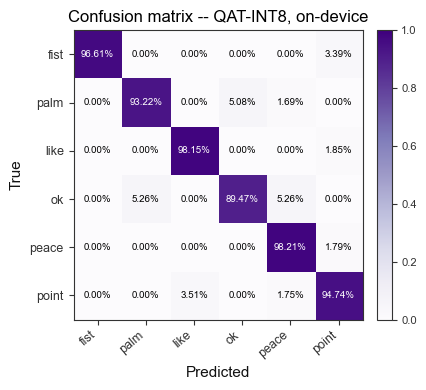

In [39]:
# =============================================================================
# Figure 9: confusion matrix -- QAT-INT8 (compare directly against the PTQ confusion
# matrix from Section 10's post-quantization analysis)
# =============================================================================

plot_confusion(best_qat_preds, best_qat_gts, "Confusion matrix -- QAT-INT8, on-device",
               "fig9_confusion_qat.png", "Purples")


In [40]:
# =============================================================================
# Research-grade summary table: fp32 / PTQ-INT8 / QAT-INT8, ready for the paper.
# Prints to stdout and writes a LaTeX table (booktabs-style via pandas.to_latex) to
# MODELS_DIR/table_fp32_ptq_qat_comparison.tex for direct \input{} into the ISAIA writeup.
# =============================================================================

import pandas as pd

metric_keys = ["accuracy", "precision", "recall", "f1_macro"]
metric_labels = {"accuracy": "Accuracy (%)", "precision": "Precision (%)",
                  "recall": "Recall (%)", "f1_macro": "F1 macro (%)"}

rows = [
    {"Model": "Float32", "Size (KB)": size_fp32_kb,
     **{metric_labels[k]: metrics_fp32[k] * 100 for k in metric_keys}},
    {"Model": "PTQ-INT8", "Size (KB)": size_int8_kb,
     **{metric_labels[k]: metrics_int8[k] * 100 for k in metric_keys}},
    {"Model": "QAT-INT8", "Size (KB)": size_qat_kb,
     **{metric_labels[k]: best_qat_metrics[k] * 100 for k in metric_keys}},
]
df_comparison = pd.DataFrame(rows).set_index("Model").round(2)
print(df_comparison.to_string())

qat_vs_ptq_delta = best_qat_metrics["f1_macro"] - metrics_int8["f1_macro"]
fp32_vs_ptq_drop = metrics_fp32["f1_macro"] - metrics_int8["f1_macro"]
fp32_vs_qat_drop = metrics_fp32["f1_macro"] - best_qat_metrics["f1_macro"]
recovered_pct = (100 * qat_vs_ptq_delta / fp32_vs_ptq_drop) if fp32_vs_ptq_drop > 0 else float("nan")

print(f"\nfp32 -> PTQ-INT8 macro-F1 drop:  {fp32_vs_ptq_drop*100:+.2f} points")
print(f"fp32 -> QAT-INT8 macro-F1 drop:  {fp32_vs_qat_drop*100:+.2f} points")
print(f"QAT vs PTQ macro-F1 delta:       {qat_vs_ptq_delta*100:+.2f} points"
      f"{f'  (recovered {recovered_pct:.0f}% of the PTQ quantization drop)' if fp32_vs_ptq_drop > 0 else ''}")

latex_path = os.path.join(MODELS_DIR, "table_fp32_ptq_qat_comparison.tex")
with open(latex_path, "w") as f:
    f.write(df_comparison.to_latex(
        float_format="%.2f",
        caption="Detection metrics and on-device size across float32, PTQ-INT8, and "
                "QAT-INT8 variants (pretrained-backbone notebook).",
        label="tab:qat_comparison_pretrained",
    ))
print(f"\nsaved LaTeX table: {latex_path}")


          Size (KB)  Accuracy (%)  Precision (%)  Recall (%)  F1 macro (%)
Model                                                                     
Float32     2283.50         79.68          95.73       79.82         86.92
PTQ-INT8     692.70         70.44          94.82       70.59         80.80
QAT-INT8     643.03         75.06          95.07       75.24         83.94

fp32 -> PTQ-INT8 macro-F1 drop:  +6.12 points
fp32 -> QAT-INT8 macro-F1 drop:  +2.98 points
QAT vs PTQ macro-F1 delta:       +3.14 points  (recovered 51% of the PTQ quantization drop)

saved LaTeX table: c:\Users\xared\Documents\30_PROJECTS\TinyGestureSSD\TinyGestureSSD\models_pretrained\table_fp32_ptq_qat_comparison.tex
